<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/08_Phishing_Detection/QRAC_EthereumPhishing_Guddanti2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QRAC-encoded QSVM and VQC for Ethereum phishing detection: Guddanti et al. (2026) step by step

This notebook re-implements, runs and checks the experiments of

> Sai Sakunthala Guddanti, Anupama Ray, Mrunal Arun Kumavat and Anil Prabhakar,
> "Detecting Phishing in Ethereum Networks using Quantum Machine Learning",
> arXiv:2607.12828 [quant-ph], 14 July 2026. https://arxiv.org/abs/2607.12828

Its predecessors, which this notebook also uses to fill gaps the 2026 text leaves open, are
Ray, Sakunthala and Prabhakar, *Improving phishing detection in Ethereum transaction network using Quantum Machine Learning*,
IEEE QCE 2023, doi:10.1109/QCE57702.2023.00125, and Ray et al., *Classical ensemble of Quantum-classical ML algorithms for
Phishing detection in Ethereum transaction networks*, arXiv:2211.00004 (2022).

**What the notebook does.** Every Ethereum account (node) is described by 7 statistics of the transaction graph (in-degree,
out-degree, degree, in-strength, out-strength, strength, number of neighbours). The notebook downloads the authors' own
train and test feature files from their public GitHub repository (pinned commit), then trains and compares
(i) a **quantum-kernel SVM (QSVM)** and (ii) a **Variational Quantum Classifier (VQC)**, each with five ways of loading the data
into qubits: the textbook **ZZ feature map** (7 qubits, real-valued features) and the paper's **Quantum Random Access Codes
(QRAC)** that squeeze the 7 binarised features into 3 or 2 qubits (3-qubit (3,1)-QRAC, 2-qubit concatenated (3,1)-QRAC and
the new 2-qubit *cascaded* (2,1)-QRAC). It also runs (iii) the annealing formulation of the SVM (a QUBO solved here by simulated
annealing, standing in for the D-Wave machine), (iv) a stacked classical ensemble of quantum and classical models, and (v) a
noisy-simulator stand-in for the IBM hardware runs. Classical SVM, LightGBM and random forest are trained on exactly the same
inputs. The last section prints the paper's numbers next to ours and gives a verdict per claim.

**How to run it.** Open it in Google Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. `FAST_MODE = True`
finishes in about 5-6 minutes; `FAST_MODE = False` (the setting of this saved run) follows the paper's budgets (COBYLA 100
iterations, full 11,000-node test set, 3 seeds) and takes about 10-15 minutes on a laptop CPU (somewhat longer on a Colab CPU). No account, token or GPU is needed: the data
come from a public GitHub repository, not from a gated Hugging Face dataset, so no Hugging Face token is involved.

**What you get at the end.** A table of macro-F1 / phishing-F1 / phishing-recall / false negatives for 20+ models, the
figures of the encodings and circuits, and a "paper vs this notebook" verdict table.

## The paper in one page

**Problem.** Find phishing accounts in the Ethereum transaction graph. Phishing nodes are rare (1,160 of about 3 million
crawled nodes, 0.039 %; labels come from public Etherscan reports), so the task is an extreme class-imbalance / anomaly problem
in which missed phishing accounts (false negatives) are the costly error.

**Decision.** Binary classification of one node from 7 graph statistics (Chen et al., 2020): phishing vs not phishing.

**Method.** (1) *QSVM-qiskit*: quantum kernel `K(x,y) = |<phi(x)|phi(y)>|^2`, classical SVM on the kernel matrix.
(2) *VQC*: feature map, `TwoLocal`-style ansatz, parity read-out (even parity = +1, odd = -1), COBYLA.
(3) *QSVM-dwave*: the SVM dual written as a QUBO (RBF kernel with sigma = 150, 2 bits of precision per Lagrange multiplier)
and solved on a quantum annealer. (4) *Stacking ensemble*: base-model predictions are appended to the features and a
meta-classifier is trained (QSVM-qiskit + GCN is the paper's best pair). The data encodings are the ZZ feature map (real
valued features, 7 qubits) and **QRAC** (features binarised at their median, grouped in 3-bit strings and each string stored
in one qubit with three U3 angles; 3-qubit (3,1)-QRAC, 2-qubit concatenated (3,1)-QRAC, and a new 2-qubit *cascaded* (2,1)-QRAC).

**Data.** 320 balanced training nodes (160 phishing, 160 not), 11,000 test nodes (1,000 phishing, 10,000 not) for all
simulator results; hardware runs on a balanced 300-node test subset with 128 shots on `ibm_kingston`.

**Claims checked here.**

| # | Claim in the paper | Where |
|---|---|---|
| C1 | Table 2 simulator rows: VQC-QRAC(3q) macro F1 0.78 / phishing F1 0.82 / recall 0.96; VQC-QRAC(2q) 0.89 / 0.90 / 0.96; QSVM-QRAC(3q) 0.94 / 0.94 / 0.95; QSVM-QRAC(2q) 0.92 / 0.92 / 0.96 | Table 2 |
| C2 | QRAC beats the ZZ feature map: +13 % for VQC, +3 % for QSVM | abstract, Sec. 6.3, Fig. 6 |
| C3 | The 2-qubit cascaded (2,1)-QRAC matches the 3-qubit (3,1)-QRAC | Sec. 6.3 |
| C4 | QSVM-qiskit has the fewest false negatives of the individual models | Sec. 6.2, Fig. 5 |
| C5 | Stacking QSVM with a complementary model reduces false negatives / raises recall | Sec. 6.2, Fig. 5 |
| C6 | QSVM-dwave (annealing): macro F1 0.78, phishing F1 0.74, recall 0.63 | QCE 2023 Table III (same data) |
| C7 | Hardware (`ibm_kingston`): QSVM loses little (0.94 -> 0.91, 0.92 -> 0.90); VQC-QRAC(2q) collapses (0.89 -> 0.61) | Table 2 |
| C8 | Dataset statistics (feature means of phishing / non-phishing nodes) | Table 1 |

Fig. 4-6 of the paper are bar charts without printed values, so only the textual statements of Sec. 6 can be checked for
them. Hardware numbers (C7) cannot be reproduced without the device; a noise-model stand-in is run for orientation only.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | 3 M crawled Ethereum nodes, "available from the authors on request" | the **authors' own feature files** `train_data.npy`, `train_labels.npy`, `test_data.npy`, `test_labels.npy` from github.com/anupamaray/EnsembleQML_application at commit `8e345c4` (Apache-2.0); first 320 training rows (160 + 160) and all 11,000 test rows, as in their notebooks |
| Train / test | 160 + 160 / 1,000 + 10,000 | identical |
| Table-2 test subset | "balanced subset of 300" | 150 + 150 nodes drawn at random from the test set, **20 draws** reported as mean +- std (which 300 nodes were used is unknown) |
| ZZ feature map | real-valued features, settings not given | `zz_feature_map(7, reps=2, entanglement="full")` (Qiskit 0.3x default of the authors' code) on the **raw** features exactly as in the authors' notebooks (`ZZ-raw`); plus a variant `ZZ-scaled` (log1p, then MinMax to [0, pi] fitted on the training split) because raw degrees up to 10^4 act as random phases |
| Binarisation | median of each feature "across the dataset" (train + test) | median of the **training split** (primary, no test information); the paper-literal median over train + test is run as an ablation |
| (3,1)-QRAC | U3 angles of QCE 2023 Table I | identical (`qrac31_angles`), state vectors and Bloch vectors asserted below |
| (2,1)-QRAC | U3(pi/4, 3pi/4, 5pi/4, 7pi/4, 0, 0) | identical |
| 2-qubit concatenated (3,1)-QRAC | third string "added to qubit 1 or 2" (Fig. 4) | added to **qubit 1** as a second U3 gate applied after the first (`# CHOICE`) |
| 2-qubit cascaded (2,1)-QRAC | four 2-bit strings, planes xy / yz / xz, angles not given | qubit 1: Ry(a) for bits 1-2 (xz plane) then Rx(g) for bits 3-4 (yz plane); qubit 2: Ry(a) for bits 5-6 then Rz(g) for bit 7 + pad (xy plane); a in {pi/4, 3pi/4, 5pi/4, 7pi/4} (the (2,1)-QRAC), g in {pi/8, 3pi/8, 5pi/8, 7pi/8} chosen so that all 16 states of a qubit are distinct (min. Bloch-vector distance 0.54, checked below) |
| VQC ansatz | not given (19 ansatze were screened) | `n_local(["ry","rz"], "cz", reps=2, entanglement="full")`, the authors' repository choice; shallow circuit as the paper recommends |
| VQC read-out | parity of the measured bit string, even = +1 | expectation value of `Z x ... x Z` (exactly the parity expectation), phishing = +1 label, squared-error loss, exact statevector (the paper trains on a noiseless statevector simulator) |
| VQC optimiser | COBYLA | COBYLA, `maxiter=100` (2022 version); random initial weights per seed |
| QSVM | `QSVC` default | `SVC(kernel="precomputed", C=1)` on `|<phi(a)|phi(b)>|^2` computed from exact statevectors; asserted equal to Qiskit's `QSVC` + `FidelityStatevectorKernel` |
| Annealing QSVM | D-Wave Leap hybrid solver, sigma = 150, precision [1, 2] | the same QUBO, solved by `dwave.samplers.SimulatedAnnealingSampler` (no D-Wave access) |
| Stacking | QSVM + GCN (needs the whole graph, 17 h training) | the authors' notebook variants QSVM + LGBM -> logistic regression and VQC -> LGBM; **GCN cannot be run here** (the graph is not public) |
| Hardware | `ibm_kingston`, 128 shots | `FakeKingston` noise model in Qiskit Aer, 128 shots, same circuits (a stand-in, not hardware); optional real run if `IBM_TOKEN` is set is not implemented |
| Seeds | not given | `SEED = 42`; VQC repeated over seeds |

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, lightgbm.
# The pip line runs on Colab (or wherever the packages are missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
_missing = [m for m in ("qiskit", "qiskit_machine_learning", "qiskit_aer", "dwave.samplers", "dimod")
            if importlib.util.find_spec(m.split(".")[0]) is None]
if IN_COLAB or _missing:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc "dimod==0.12.22" "dwave-samplers==1.8.0"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("Qiskit stack and dwave-samplers already present; skipping pip install.")

Qiskit stack and dwave-samplers already present; skipping pip install.


In [2]:
# ---------------- configuration (every tunable constant lives here) ----------------
FAST_MODE   = False       # True: class demo (about 5-6 min). False: the paper's budgets (COBYLA 100, 11,000 test nodes, 3 seeds; about 10-15 min).
SEED        = 42          # CHOICE: the paper gives no seed
IBM_TOKEN   = ""          # optional; real-hardware cells are not implemented here, the fake-backend stand-in needs no token

DATA_DIR    = "qc066_data"                       # cache for the downloaded .npy files
REPO        = "anupamaray/EnsembleQML_application"
REPO_SHA    = "8e345c43f1b736e571dfebabe66225b32a3b4197"   # pinned commit of the authors' repository
N_TRAIN_PER_CLASS = 160                          # paper: 160 phishing + 160 non-phishing training nodes
N_TEST_FAST = 2200                               # FAST_MODE: stratified test subset (200 phishing + 2000 not)
N_BAL_DRAWS = 20                                 # random balanced 150+150 test subsets for the Table-2 comparison

N_SEEDS     = 1 if FAST_MODE else 3              # VQC repetitions with different initial weights
VQC_MAXITER = 30 if FAST_MODE else 100           # paper (2022 version): COBYLA maxiter = 100
SIGMA       = 150.0                              # paper: RBF sigma of the annealing QSVM
QA_PRECISION = (1, 2)                            # paper: precision vector p = [2^0, 2^1]
QA_READS    = 10 if FAST_MODE else 50            # simulated-annealing restarts
QA_SWEEPS   = 1000
HW_SHOTS    = 128                                # paper: 128 shots on ibm_kingston
HW_N_TEST   = 60 if FAST_MODE else 300           # balanced test nodes for the noisy-simulator stand-in
BIN_MODES   = ["train"] if FAST_MODE else ["train", "paper"]   # median from the training split / from train+test (paper-literal)

In [3]:
import os, time, urllib.request, warnings, hashlib
os.environ.setdefault("QISKIT_PARALLEL", "FALSE")      # one process: predictable timing, no multiprocessing surprises in notebooks
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
from sklearn.model_selection import StratifiedKFold
try:
    import lightgbm as lgb
    LGBM = lambda: lgb.LGBMClassifier(random_state=SEED, verbose=-1, n_jobs=1)
    LGBM_NAME = "LGBM"
except Exception:                                  # CHOICE: fallback so that the notebook never stops on a missing wheel
    from sklearn.ensemble import HistGradientBoostingClassifier
    LGBM = lambda: HistGradientBoostingClassifier(random_state=SEED)
    LGBM_NAME = "HistGB (LightGBM substitute)"

import qiskit, qiskit_machine_learning, qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import zz_feature_map, n_local
from qiskit.quantum_info import Statevector, SparsePauliOp, Operator
from qiskit.primitives import StatevectorEstimator
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals
import dimod
from dwave.samplers import SimulatedAnnealingSampler

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| qiskit-aer", qiskit_aer.__version__, "| dimod", dimod.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| gradient boosting:", LGBM_NAME)
print("FAST_MODE =", FAST_MODE, "| seeds =", N_SEEDS, "| VQC maxiter =", VQC_MAXITER)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | qiskit-aer 0.17.2 | dimod 0.12.22
numpy 2.5.4 | pandas 3.0.6 | gradient boosting: LGBM
FAST_MODE = False | seeds = 3 | VQC maxiter = 100


## 1. The data: the authors' Ethereum feature files

The paper's crawl (3 million nodes) is "available from the authors upon request", but the authors published the exact files
they used for the experiments in the `codes/` folder of their repository (commit `8e345c4`, 2022-10-28, Apache-2.0):
`train_data.npy` (960 x 7: the first 160 rows are phishing nodes, the next 800 are non-phishing), `test_data.npy`
(11,000 x 7: 1,000 phishing then 10,000 non-phishing) and the matching one-hot label files (`[1, 0]` = phishing, `[0, 1]` = not).
Their notebooks take the first 320 training rows (160 phishing + 160 non-phishing) to keep the training set balanced; we do the
same. The cell downloads the files (raw.githubusercontent.com, with a jsDelivr mirror as fallback), caches them in `DATA_DIR`
and also accepts files you place there yourself (offline use).

The 7 features are statistics of the directed transaction multigraph: **in-degree / out-degree / degree** (number of incoming /
outgoing / all transactions), **in-strength / out-strength / strength** (ether received / sent / total) and the **number of distinct
neighbours** (Chen et al., 2020).

In [4]:
FEATURES = ["in_degree", "out_degree", "degree", "in_strength", "out_strength", "strength", "n_neighbors"]
FILES = ["train_data.npy", "train_labels.npy", "test_data.npy", "test_labels.npy"]
MIRRORS = [f"https://raw.githubusercontent.com/{REPO}/{REPO_SHA}/codes/{{f}}",
           f"https://cdn.jsdelivr.net/gh/{REPO}@{REPO_SHA}/codes/{{f}}",
           f"https://github.com/{REPO}/raw/{REPO_SHA}/codes/{{f}}"]

def fetch(fname):
    path = os.path.join(DATA_DIR, fname)
    if os.path.exists(path) and os.path.getsize(path) > 1000:
        return path
    last = None
    for tpl in MIRRORS:
        try:
            urllib.request.urlretrieve(tpl.format(f=fname), path)
            if os.path.getsize(path) > 1000:
                return path
        except Exception as e:
            last = e
    raise RuntimeError(f"could not download {fname} ({last}); place the four .npy files from {REPO}/codes in {DATA_DIR}/")

raw = {f: np.load(fetch(f)) for f in FILES}
for f, a in raw.items():
    print(f"{f:18s} shape={a.shape} dtype={a.dtype} sha256={hashlib.sha256(open(os.path.join(DATA_DIR, f), 'rb').read()).hexdigest()[:12]}")

# one-hot labels: column 0 == 1 means phishing (first 160 training rows / first 1000 test rows)
LABEL_NAMES = {0: "non-phishing", 1: "phishing"}
Xtr_all, ytr_all = raw["train_data.npy"].astype(np.float64), raw["train_labels.npy"][:, 0]
Xte_all, yte_all = raw["test_data.npy"].astype(np.float64), raw["test_labels.npy"][:, 0]

# training set exactly as in the authors' notebooks: first 320 rows = 160 phishing + 160 non-phishing
assert ytr_all[:160].all() and not ytr_all[160:320].any()
X_tr, y_tr = Xtr_all[:2 * N_TRAIN_PER_CLASS], ytr_all[:2 * N_TRAIN_PER_CLASS]
assert (Xte_all[:1000].shape[0] == 1000) and yte_all[:1000].all() and not yte_all[1000:].any()

# FAST_MODE evaluates on a stratified subset of the test set; the full run uses all 11,000 nodes
if FAST_MODE:
    r = np.random.default_rng(SEED)
    sel = np.sort(np.r_[r.choice(1000, N_TEST_FAST // 11, replace=False),
                        1000 + r.choice(10000, N_TEST_FAST - N_TEST_FAST // 11, replace=False)])
else:
    sel = np.arange(len(yte_all))
X_te, y_te = Xte_all[sel], yte_all[sel]

# the random balanced 150+150 subsets used for the paper's Table-2 style evaluation (hardware used 300 test nodes)
BAL_DRAWS = []
for d in range(N_BAL_DRAWS):
    r = np.random.default_rng(SEED + d)
    BAL_DRAWS.append(np.r_[r.choice(np.flatnonzero(y_te == 1), 150, replace=False),
                           r.choice(np.flatnonzero(y_te == 0), 150, replace=False)])
print(f"\ntrain: {X_tr.shape}, phishing={int(y_tr.sum())}, non-phishing={int((1 - y_tr).sum())}")
print(f"test : {X_te.shape}, phishing={int(y_te.sum())}, non-phishing={int((1 - y_te).sum())}  (FAST_MODE={FAST_MODE})")

train_data.npy     shape=(960, 7) dtype=float32 sha256=bfffe5f1c1ff
train_labels.npy   shape=(960, 2) dtype=int64 sha256=5ec2a32563fc
test_data.npy      shape=(11000, 7) dtype=float32 sha256=be9b15ab58ba
test_labels.npy    shape=(11000, 2) dtype=int64 sha256=c24809b1f959

train: (320, 7), phishing=160, non-phishing=160
test : (11000, 7), phishing=1000, non-phishing=10000  (FAST_MODE=False)


## Dataset Exploration and Visualisation

Everything below uses the **real observations** of the authors' files: no data are simulated or invented. The labels are binary
(phishing / non-phishing); the data set has no finer attack families. The plots show (a) the class balance of the training
and test sets, (b) the per-class feature statistics next to the paper's Table 1, and (c) a 2-D PCA view of the real nodes
coloured by their ground-truth label, first as raw PCA coordinates (fitted on the training split only) and then rescaled to
the angle range [0, pi] that an angle-encoding feature map would use.

Training set: (320, 7) | test set: (11000, 7) | features: ['in_degree', 'out_degree', 'degree', 'in_strength', 'out_strength', 'strength', 'n_neighbors']
Original label files are one-hot ([1, 0] = phishing, [0, 1] = non-phishing); decoded values: [(0, 'non-phishing'), (1, 'phishing')]


,train (320 used),train (960 file),test (used),"test (11,000 file)"
non-phishing,160,800,10000,10000
phishing,160,160,1000,1000


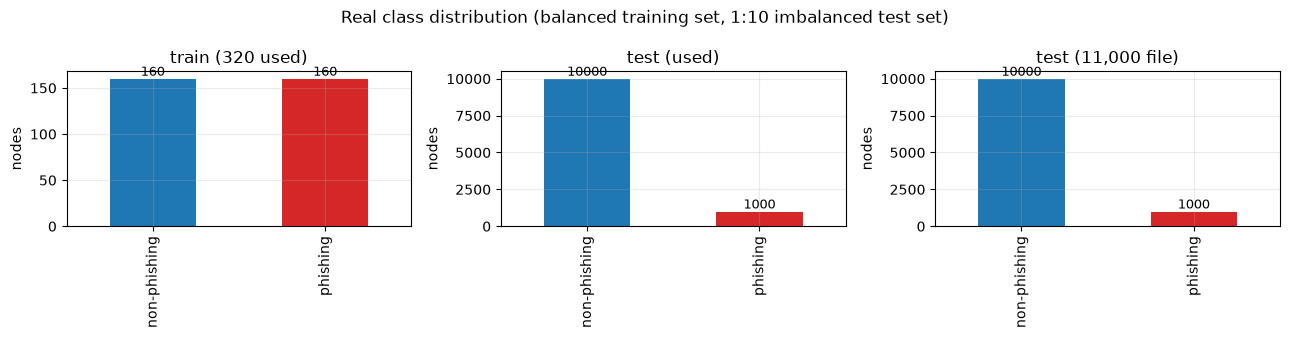

In [5]:
# ---- (a) shape, feature names, original label values, class counts, bar chart ----
print("Training set:", X_tr.shape, "| test set:", X_te.shape, "| features:", FEATURES)
print("Original label files are one-hot ([1, 0] = phishing, [0, 1] = non-phishing); decoded values:", sorted(LABEL_NAMES.items()))
cnt = pd.DataFrame({
    "train (320 used)":  pd.Series(y_tr).map(LABEL_NAMES).value_counts(),
    "train (960 file)":  pd.Series(ytr_all).map(LABEL_NAMES).value_counts(),
    "test (used)":       pd.Series(y_te).map(LABEL_NAMES).value_counts(),
    "test (11,000 file)": pd.Series(yte_all).map(LABEL_NAMES).value_counts()})
display(cnt)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a, col in zip(ax, ["train (320 used)", "test (used)", "test (11,000 file)"]):
    cnt[col].reindex(["non-phishing", "phishing"]).plot.bar(ax=a, color=["tab:blue", "tab:red"])
    a.set_title(col); a.set_ylabel("nodes")
    for p in a.patches: a.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.suptitle("Real class distribution (balanced training set, 1:10 imbalanced test set)"); plt.tight_layout(); plt.show()

In [6]:
# ---- (b) per-class feature statistics vs the paper's Table 1 ----
PAPER_T1 = {  # Table 1 of the paper (1,160 phishing / 10,800 non-phishing nodes)
    "phishing mean":     [31.39, 20.49, 51.88, 78.61, 86.73, 165.34, 31.69],
    "non-phishing mean": [4.50, 4.64, 9.14, 72.53, 9.25, 81.78, 3.64],
    "phishing std":      [180.99, 96.83, 219.73, 691.29, 860.10, 1390.35, 106.39],
    "non-phishing std":  [154.35, 101.32, 192.20, 4409.68, 281.02, 4421.54, 79.36]}
full_te = pd.DataFrame(Xte_all, columns=FEATURES); lab = yte_all
mine = {"phishing mean": full_te[lab == 1].mean().values, "non-phishing mean": full_te[lab == 0].mean().values,
        "phishing std": full_te[lab == 1].std().values, "non-phishing std": full_te[lab == 0].std().values}
t1 = pd.DataFrame({f"{k} (paper)": PAPER_T1[k] for k in PAPER_T1}, index=FEATURES)
for k in mine: t1[f"{k} (test file)"] = mine[k]
print("Test file (1,000 phishing + 10,000 non-phishing nodes) vs the paper's Table 1 (all 1,160 + 10,800 nodes):")
display(t1.round(2)[[c for k in PAPER_T1 for c in (f"{k} (paper)", f"{k} (test file)")]])
print("\nTraining file per-class means (first 160 phishing | next 160 non-phishing | all 800 non-phishing):")
display(pd.DataFrame({"phishing (160)": X_tr[y_tr == 1].mean(0), "non-phishing (160)": X_tr[y_tr == 0].mean(0),
                      "non-phishing (800 in file)": Xtr_all[160:].mean(0)}, index=FEATURES).round(2))

Test file (1,000 phishing + 10,000 non-phishing nodes) vs the paper's Table 1 (all 1,160 + 10,800 nodes):


,phishing mean (paper),phishing mean (test file),non-phishing mean (paper),non-phishing mean (test file),phishing std (paper),phishing std (test file),non-phishing std (paper),non-phishing std (test file)
in_degree,31.39,29.13,4.50,4.75,180.99,171.27,154.35,160.32
out_degree,20.49,19.57,4.64,4.79,96.83,98.91,101.32,105.19
degree,51.88,48.71,9.14,9.54,219.73,214.09,192.20,199.61
in_strength,78.61,84.15,72.53,77.79,691.29,743.61,4409.68,4582.71
out_strength,86.73,94.71,9.25,9.53,860.10,925.72,281.02,291.42
strength,165.34,178.86,81.78,87.32,1390.35,1495.68,4421.54,4594.99
n_neighbors,31.69,29.52,3.64,3.79,106.39,83.12,79.36,82.46



Training file per-class means (first 160 phishing | next 160 non-phishing | all 800 non-phishing):


,phishing (160),non-phishing (160),non-phishing (800 in file)
in_degree,45.54,0.57,1.42
out_degree,26.22,1.84,2.86
degree,71.76,2.41,4.28
in_strength,43.97,2.27,6.83
out_strength,36.91,6.34,5.86
strength,80.88,8.61,12.70
n_neighbors,45.28,1.49,1.84


PCA explained variance ratio (train fit): [0.736 0.132]


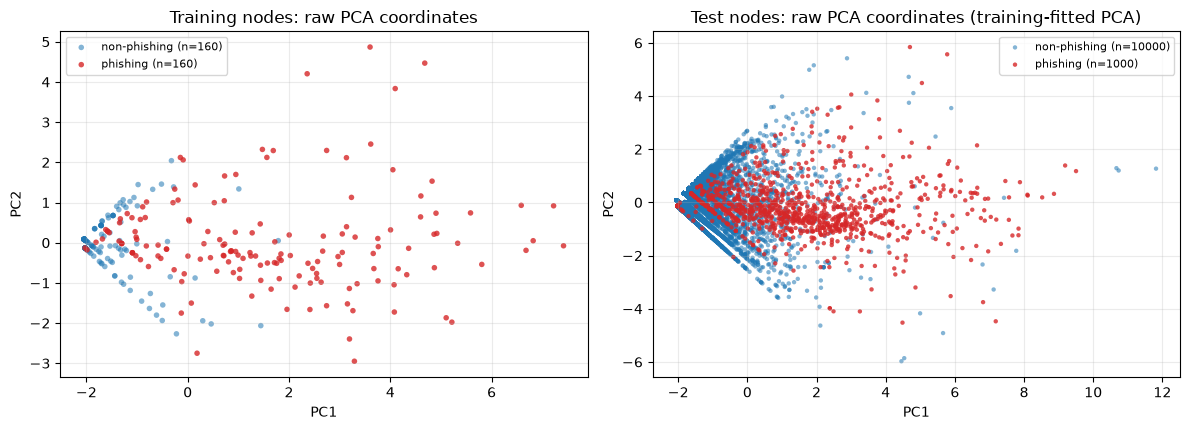

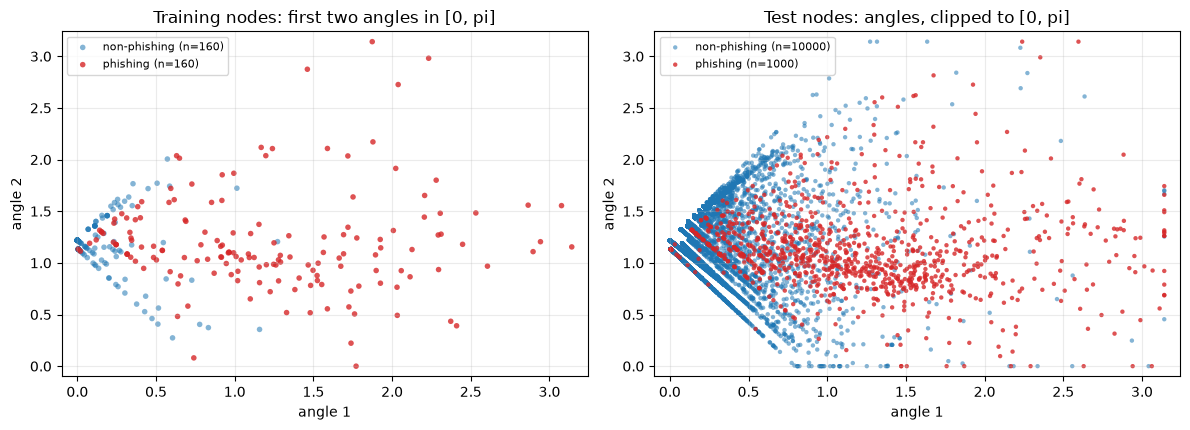

In [7]:
# ---- (c) 2-D scatter of real nodes coloured by ground truth: raw PCA coordinates, then angles in [0, pi] ----
# CHOICE: log1p first (degrees and strengths span 5 orders of magnitude); every transform is fitted on the training split only.
sc_pca = StandardScaler().fit(np.log1p(X_tr)); pca2 = PCA(n_components=2, random_state=SEED).fit(sc_pca.transform(np.log1p(X_tr)))
P_tr = pca2.transform(sc_pca.transform(np.log1p(X_tr))); P_te = pca2.transform(sc_pca.transform(np.log1p(X_te)))
ang = MinMaxScaler((0, np.pi)).fit(P_tr)
A_tr = ang.transform(P_tr); A_te = np.clip(ang.transform(P_te), 0, np.pi)
print("PCA explained variance ratio (train fit):", pca2.explained_variance_ratio_.round(3))

COL = {0: "tab:blue", 1: "tab:red"}
def scatter(ax, P, y, title, xl, yl, s=10):
    for c in (0, 1):
        m = y == c
        ax.scatter(P[m, 0], P[m, 1], s=s, c=COL[c], alpha=0.55 if c == 0 else 0.8, label=f"{LABEL_NAMES[c]} (n={int(m.sum())})", edgecolors="none")
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(fontsize=8)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
scatter(ax[0], P_tr, y_tr, "Training nodes: raw PCA coordinates", "PC1", "PC2", s=16)
scatter(ax[1], P_te, y_te, "Test nodes: raw PCA coordinates (training-fitted PCA)", "PC1", "PC2")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
scatter(ax[0], A_tr, y_tr, "Training nodes: first two angles in [0, pi]", "angle 1", "angle 2", s=16)
scatter(ax[1], A_te, y_te, "Test nodes: angles, clipped to [0, pi]", "angle 1", "angle 2")
for a in ax: a.set_xlim(-0.1, np.pi + 0.1); a.set_ylim(-0.1, np.pi + 0.1)
plt.tight_layout(); plt.show()

## 2. Preprocessing and the five data encodings

All five encodings start from the same 320 training nodes. Two kinds of input are produced:

* **Real-valued angles** for the ZZ feature map: either the raw features (`ZZ-raw`, exactly what the authors' notebooks do) or
  `log1p` features min-max scaled to [0, pi] with the training split's minimum and maximum (`ZZ-scaled`, test values clipped).
* **Bits** for QRAC: every feature is compared with its **median** (value above the median -> `1`, otherwise `0`). The primary
  setting takes the median of the *training split*; the paper takes it "across the entire training and testing data set"
  (label-free but it uses the test features), which is run as an ablation (`BIN_MODES`).

A QRAC stores several bits in one qubit through one U3 gate. The seven bits are grouped as in the paper:
`[in-deg, out-deg, deg]`, `[in-str, out-str, str]`, `[n-neighbours, 0, 0]` (padded). The three schemes differ in how those
groups are laid out on qubits:

| Scheme | Qubits | Layout |
|---|---|---|
| `QRAC-3q(3,1)` | 3 | one (3,1)-QRAC per qubit |
| `QRAC-2q(3,1)` | 2 | the third (3,1)-QRAC is applied on top of the first qubit's state (concatenation) |
| `QRAC-2q(2,1)` | 2 | cascaded (2,1)-QRACs on the bits in feature order: qubit 1 = Ry(a) then Rx(g), qubit 2 = Ry(a) then Rz(g) |
| `QRAC-2q(2,1) grouped` | 2 | sensitivity variant, not in the paper and added after the literal-order cascade had been evaluated (so it is a sensitivity analysis, not a model selected on clean data): same cascade, but the degree features and the neighbour count sit on qubit 1 and the strength features on qubit 2 |

The U3 angles are the ones printed in the 2023 paper (Table I): with `theta = acos(sqrt(1/2 + sqrt(3)/6))`, bit string `b1 b2 b3`
-> `U3(2 theta or pi - 2 theta, +-pi/4 or +-3pi/4, minus the same)`. The cell below builds them and **asserts** that the 8 states
have Bloch vectors `(+-1,+-1,+-1)/sqrt(3)` (cube corners) and the 4 (2,1)-states Bloch vectors `(+-1,0,+-1)/sqrt(2)` (square corners),
so any typo would stop the notebook.

In [8]:
# ---------------- QRAC angle tables ----------------
THETA = np.arccos(np.sqrt(0.5 + np.sqrt(3) / 6))
def qrac31_angles(b1, b2, b3):
    """U3(theta, phi, lambda) for a 3-bit string, QCE-2023 Table I."""
    th = 2 * THETA if b1 == 0 else np.pi - 2 * THETA
    base = np.pi / 4 if b2 == 0 else 3 * np.pi / 4
    phi = base if b3 == 0 else -base
    return (th, phi, -phi)
QRAC21 = {(0, 0): np.pi / 4, (1, 0): 3 * np.pi / 4, (1, 1): 5 * np.pi / 4, (0, 1): 7 * np.pi / 4}   # 2023 paper: '00','10','11','01'
CASC_G = {(0, 0): np.pi / 8, (1, 0): 3 * np.pi / 8, (1, 1): 5 * np.pi / 8, (0, 1): 7 * np.pi / 8}   # CHOICE: half-angle (2,1) points, see below
def u3_state(th, ph, la):
    return Statevector([np.cos(th / 2), np.exp(1j * ph) * np.sin(th / 2)])      # U3(th, ph, la)|0>
def bloch(sv):
    p = sv.data; return np.real([np.conj(p) @ (m @ p) for m in (np.array([[0, 1], [1, 0]]), np.array([[0, -1j], [1j, 0]]), np.diag([1., -1.]))])

# (3,1)-QRAC: 8 states on the corners of a cube
B31 = {b: bloch(u3_state(*qrac31_angles(*b))) for b in np.ndindex(2, 2, 2)}
for b, v in B31.items():
    assert np.allclose(np.abs(v), 1 / np.sqrt(3), atol=1e-9), (b, v)
assert len({tuple(np.round(v, 6)) for v in B31.values()}) == 8
rec31 = 0.5 + 0.5 / np.sqrt(3)
# (2,1)-QRAC: 4 states on the corners of a square (xz plane)
B21 = {b: bloch(u3_state(QRAC21[b], 0, 0)) for b in QRAC21}
for b, v in B21.items():
    assert np.allclose(np.abs(v[[0, 2]]), 1 / np.sqrt(2), atol=1e-9) and abs(v[1]) < 1e-9, (b, v)
rec21 = 0.5 + 0.5 / np.sqrt(2)
print(f"(3,1)-QRAC: 8 distinct Bloch vectors (+-1,+-1,+-1)/sqrt(3); bit-recovery probability = {rec31:.3f}  (paper: 0.78)")
print(f"(2,1)-QRAC: 4 distinct Bloch vectors (+-1,0,+-1)/sqrt(2);   bit-recovery probability = {rec21:.3f}  (paper: 0.85)")

# cascaded (2,1)-QRAC on one qubit: Ry(a) then Rx(g) (or Rz(g)); check that all 16 combinations are distinguishable
def rot(axis, g):
    c, s = np.cos(g / 2), np.sin(g / 2)
    return {"x": np.array([[c, -1j * s], [-1j * s, c]]), "y": np.array([[c, -s], [s, c]]), "z": np.diag([np.exp(-1j * g / 2), np.exp(1j * g / 2)])}[axis]
for ax2 in ("x", "z"):
    pts = [bloch(Statevector(rot(ax2, CASC_G[g]) @ rot("y", QRAC21[a]) @ np.array([1, 0], complex))) for a in QRAC21 for g in CASC_G]
    dmin = min(np.linalg.norm(p - q) for i, p in enumerate(pts) for q in pts[i + 1:])
    print(f"cascade Ry(a) then R{ax2}(g): 16 states, minimum Bloch-vector distance {dmin:.3f}")
    assert dmin > 0.5

(3,1)-QRAC: 8 distinct Bloch vectors (+-1,+-1,+-1)/sqrt(3); bit-recovery probability = 0.789  (paper: 0.78)
(2,1)-QRAC: 4 distinct Bloch vectors (+-1,0,+-1)/sqrt(2);   bit-recovery probability = 0.854  (paper: 0.85)
cascade Ry(a) then Rx(g): 16 states, minimum Bloch-vector distance 0.541
cascade Ry(a) then Rz(g): 16 states, minimum Bloch-vector distance 0.541


In [9]:
# ---------------- feature-map circuits for the three QRAC schemes ----------------
# layout[q] is the list of U3 gates on qubit q: (kind, bit indices); bit index 7 is a constant 0 (padding)
SCHEMES = {
    "QRAC-3q(3,1)": {"n": 3, "layout": [[("q31", (0, 1, 2))], [("q31", (3, 4, 5))], [("q31", (6, 7, 7))]]},
    "QRAC-2q(3,1)": {"n": 2, "layout": [[("q31", (0, 1, 2)), ("q31", (6, 7, 7))], [("q31", (3, 4, 5))]]},   # CHOICE: third string on qubit 1
    "QRAC-2q(2,1)": {"n": 2, "layout": [[("q21", (0, 1)), ("rx", (2, 3))], [("q21", (4, 5)), ("rz", (6, 7))]]},  # CHOICE: planes xz+yz, xz+xy; bits in feature order
    # sensitivity variant (not in the paper): the same cascade, but degree features + neighbours on qubit 1 and strength features on qubit 2
    "QRAC-2q(2,1) grouped": {"n": 2, "layout": [[("q21", (0, 1)), ("rx", (2, 6))], [("q21", (3, 4)), ("rz", (5, 7))]]},
}
def gate_angles(kind, bits):
    if kind == "q31": return qrac31_angles(*bits)
    if kind == "q21": return (QRAC21[tuple(bits)], 0.0, 0.0)             # U3(a,0,0) = Ry(a)
    if kind == "rx":  return (CASC_G[tuple(bits)], -np.pi / 2, np.pi / 2)  # U3(g,-pi/2,pi/2) = Rx(g)
    if kind == "rz":  return (0.0, 0.0, CASC_G[tuple(bits)])              # U3(0,0,g) = Rz(g) up to a global phase
    raise ValueError(kind)

def qrac_feature_map(scheme):
    spec = SCHEMES[scheme]; n_gates = sum(len(g) for g in spec["layout"])
    x = ParameterVector("x", 3 * n_gates); qc = QuantumCircuit(spec["n"], name=scheme); k = 0
    for q, gates in enumerate(spec["layout"]):
        for _ in gates:
            qc.u(x[3 * k], x[3 * k + 1], x[3 * k + 2], q); k += 1
    return qc

def qrac_angles(bits, scheme):
    """(n_nodes, 7) bit matrix -> (n_nodes, 3 * n_gates) U3 angle matrix in the circuit's parameter order."""
    b8 = np.c_[bits, np.zeros(len(bits), dtype=int)]                    # column 7 = padding zero
    cols = []
    for gates in SCHEMES[scheme]["layout"]:
        for kind, idx in gates:
            cols.append(np.array([gate_angles(kind, b8[i, list(idx)]) for i in range(len(b8))]))   # (n, 3)
    return np.concatenate(cols, axis=1)

# an executed-state check: the 3-qubit scheme applied to a known bit string gives the product of the three single-qubit states
fm_chk = qrac_feature_map("QRAC-3q(3,1)")
bits_chk = np.array([[0, 1, 1, 0, 1, 0, 1]])                                 # the paper's example point, strings 011 | 010 | 100
st = Statevector(fm_chk.assign_parameters(qrac_angles(bits_chk, "QRAC-3q(3,1)")[0]))
ref = u3_state(*qrac31_angles(1, 0, 0)).tensor(u3_state(*qrac31_angles(0, 1, 0))).tensor(u3_state(*qrac31_angles(0, 1, 1)))
assert abs(abs(np.vdot(ref.data, st.data)) - 1) < 1e-9
print("paper example [0,1,1,0,1,0,1] -> strings 011 | 010 | 100 : feature-map state equals the product of the three QRAC states.")

paper example [0,1,1,0,1,0,1] -> strings 011 | 010 | 100 : feature-map state equals the product of the three QRAC states.


### Building the five encodings

`make_encoding(name, mode)` returns the feature-map circuit and a function `transform(X)` that turns raw nodes into the circuit's
parameter vector. **Every statistic (median, min, max) is computed from the training split only.** The ZZ feature map is the
Qiskit circuit library's `zz_feature_map(7, reps=2, entanglement="full")`.

In [10]:
ENCODINGS = ["ZZ-raw", "ZZ-scaled", "QRAC-3q(3,1)", "QRAC-2q(3,1)", "QRAC-2q(2,1)", "QRAC-2q(2,1) grouped"]

def make_encoding(name, mode="train"):
    if name.startswith("ZZ"):
        fm = zz_feature_map(7, reps=2, entanglement="full", parameter_prefix="x")
        if name == "ZZ-raw":
            tf = lambda X: np.asarray(X, float)                                  # as in the authors' notebooks
        else:
            mm = MinMaxScaler((0, np.pi)).fit(np.log1p(X_tr))                    # fitted on the training split only
            tf = lambda X, mm=mm: np.clip(mm.transform(np.log1p(X)), 0, np.pi)
    else:
        thr = np.median(X_tr, axis=0) if mode == "train" else np.median(np.vstack([X_tr, Xte_all]), axis=0)
        fm = qrac_feature_map(name)
        tf = lambda X, thr=thr, name=name: qrac_angles((np.asarray(X) > thr).astype(int), name)
    return {"name": name, "mode": mode, "fm": fm, "n": fm.num_qubits, "tf": tf}

ENC = {(n, "train"): make_encoding(n, "train") for n in ENCODINGS}
for m in BIN_MODES:
    if m != "train":
        for n in ENCODINGS[2:]:
            ENC[(n, m)] = make_encoding(n, m)
THR_TRAIN = np.median(X_tr, axis=0); THR_PAPER = np.median(np.vstack([X_tr, Xte_all]), axis=0)
print(pd.DataFrame({"median (train split)": THR_TRAIN, "median (train + test, paper-literal)": THR_PAPER}, index=FEATURES).round(3))
for k, e in ENC.items():
    if k[1] == "train":
        print(f"{k[0]:14s} qubits={e['n']}  input parameters={e['fm'].num_parameters:2d}  decomposed depth={e['fm'].decompose().decompose().depth()}")

              median (train split)  median (train + test, paper-literal)
in_degree                    1.000                                 0.000
out_degree                   1.000                                 1.000
degree                       3.000                                 1.000
in_strength                  0.244                                 0.000
out_strength                 0.054                                 0.000
strength                     1.077                                 0.039
n_neighbors                  2.000                                 1.000


ZZ-raw         qubits=7  input parameters= 7  decomposed depth=58
ZZ-scaled      qubits=7  input parameters= 7  decomposed depth=58
QRAC-3q(3,1)   qubits=3  input parameters= 9  decomposed depth=1
QRAC-2q(3,1)   qubits=2  input parameters= 9  decomposed depth=2
QRAC-2q(2,1)   qubits=2  input parameters=12  decomposed depth=2
QRAC-2q(2,1) grouped qubits=2  input parameters=12  decomposed depth=2


distinct 7-bit patterns: train 39 (of 320 nodes), test 72 (of 11000); max possible 128


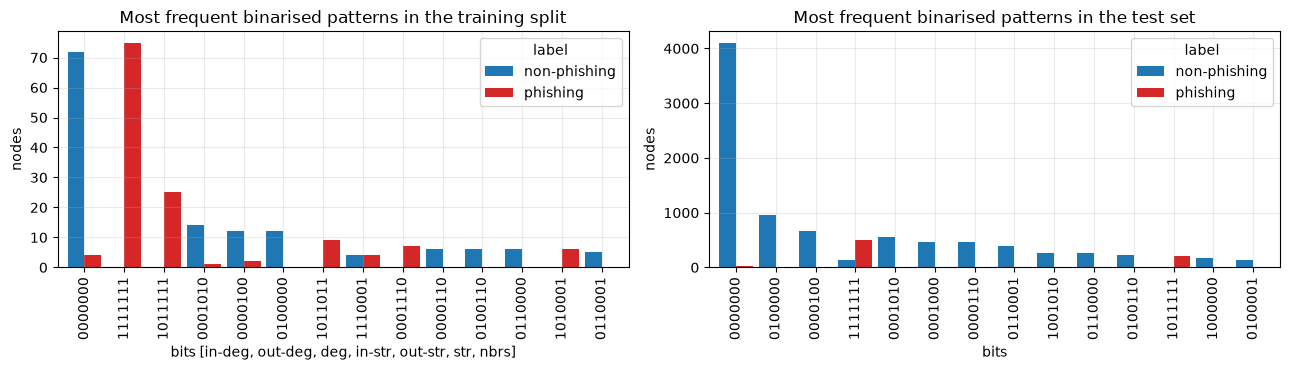

In [11]:
# ---- what the QRAC bit patterns look like for real nodes: 7 bits -> at most 128 distinct inputs ----
bits_tr = (X_tr > THR_TRAIN).astype(int); bits_te = (X_te > THR_TRAIN).astype(int)
pat = lambda B: pd.Series(["".join(map(str, r)) for r in B])
d = pd.DataFrame({"pattern": pat(bits_tr), "label": pd.Series(y_tr).map(LABEL_NAMES)})
top = d.groupby(["pattern", "label"]).size().unstack(fill_value=0)
top["total"] = top.sum(1); top = top.sort_values("total", ascending=False).head(14)
print(f"distinct 7-bit patterns: train {pat(bits_tr).nunique()} (of 320 nodes), test {pat(bits_te).nunique()} (of {len(bits_te)}); max possible 128")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
top[["non-phishing", "phishing"]].plot.bar(ax=ax[0], color=["tab:blue", "tab:red"], width=0.85)
ax[0].set_title("Most frequent binarised patterns in the training split"); ax[0].set_xlabel("bits [in-deg, out-deg, deg, in-str, out-str, str, nbrs]"); ax[0].set_ylabel("nodes")
dd = pd.DataFrame({"pattern": pat(bits_te), "label": pd.Series(y_te).map(LABEL_NAMES)}).groupby(["pattern", "label"]).size().unstack(fill_value=0)
dd["total"] = dd.sum(1); dd = dd.sort_values("total", ascending=False).head(14)
dd[["non-phishing", "phishing"]].plot.bar(ax=ax[1], color=["tab:blue", "tab:red"], width=0.85)
ax[1].set_title("Most frequent binarised patterns in the test set"); ax[1].set_xlabel("bits"); ax[1].set_ylabel("nodes")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The circuits below are the objects that are actually simulated later: the same `QuantumCircuit` instances are passed to
`Statevector` (QSVM kernels) and `EstimatorQNN` (VQC). Each VQC circuit is `feature map -> ansatz`, and its read-out is the
parity of the measured bit string, which is the expectation value of `Z x ... x Z`; a cell asserts that this expectation
equals the parity computed from the measurement probabilities, and the figures append the measurements. The QSVM kernel
circuit is the compute-uncompute circuit `phi(x_j)^dagger phi(x_i)` of the paper's Sec. 3.4.

**Assumptions where the paper omits circuit details**: the VQC ansatz (`ry`, `rz` rotations, `cz` entanglers, `full`
entanglement, 2 repetitions, final rotation layer: the authors' repository choice), the placement of the third (3,1)-QRAC on
qubit 1 for the 2-qubit scheme, the angles of the cascaded (2,1)-QRAC second stage, and the ZZ-map repetitions (2). The
annealing QSVM is a QUBO, not a gate circuit, and has no drawing (see Sec. 7).

In [12]:
def make_ansatz(n):
    return n_local(n, ["ry", "rz"], "cz", entanglement="full", reps=2, parameter_prefix="w")   # CHOICE: authors' TwoLocal(['ry','rz'],'cz',reps=2)

def bind(qc, fm, ans, a, w):
    """Bind input angles a to the feature-map parameters and weights w to the ansatz parameters (by object, not by name order)."""
    return qc.assign_parameters({**dict(zip(fm.parameters, a)), **dict(zip(ans.parameters, w))})

def show_circuit(c, title, **kw):
    fig = c.draw("mpl", **kw); fig.suptitle(title, fontsize=10, y=1.0); display(fig); plt.close(fig)

def make_qnn(fm, ans):
    qc = QuantumCircuit(fm.num_qubits); qc.compose(fm, inplace=True); qc.compose(ans, inplace=True)
    qnn = EstimatorQNN(circuit=qc, input_params=list(fm.parameters), weight_params=list(ans.parameters),
                       observables=SparsePauliOp("Z" * fm.num_qubits), estimator=StatevectorEstimator(), input_gradients=False,
                       default_precision=0.0)          # exact expectation values (the default 1/64 would add sampling noise)
    return qnn, qc

rows = []
for (name, mode), e in ENC.items():
    if mode != "train": continue
    ans = make_ansatz(e["n"]); full = QuantumCircuit(e["n"]); full.compose(e["fm"], inplace=True); full.compose(ans, inplace=True)
    dec = full.decompose().decompose().decompose()
    rows.append({"encoding": name, "qubits": e["n"], "input params": e["fm"].num_parameters, "trainable weights": ans.num_parameters,
                 "depth (VQC, decomposed)": dec.depth(), "2-qubit gates": dec.count_ops().get("cz", 0) + dec.count_ops().get("cx", 0)})
print("VQC circuits (feature map + ansatz):"); display(pd.DataFrame(rows))

# equivalence: <Z x ... x Z> equals P(even parity) - P(odd parity) from the measurement distribution
e = ENC[("QRAC-2q(3,1)", "train")]; ans = make_ansatz(e["n"]); qnn_chk, qc_chk = make_qnn(e["fm"], ans)
w_chk = np.random.default_rng(SEED).uniform(0, 2 * np.pi, ans.num_parameters); a_chk = e["tf"](X_te[:5])
exp_val = qnn_chk.forward(a_chk, w_chk)[:, 0]
par = []
for a in a_chk:
    p = Statevector(bind(qc_chk, e["fm"], ans, a, w_chk)).probabilities_dict()
    par.append(sum(v * (1 if bin(int(k, 2)).count("1") % 2 == 0 else -1) for k, v in p.items()))
assert np.allclose(exp_val, par, atol=1e-8)
print("check: EstimatorQNN output (expectation of Z..Z) == P(even) - P(odd) of the measured bit string  ->", np.round(exp_val, 4))

VQC circuits (feature map + ansatz):


,encoding,qubits,input params,trainable weights,"depth (VQC, decomposed)",2-qubit gates
0,ZZ-raw,7,7,42,101,126
1,ZZ-scaled,7,7,42,101,126
2,"QRAC-3q(3,1)",3,9,18,20,6
3,"QRAC-2q(3,1)",2,9,12,13,2
4,"QRAC-2q(2,1)",2,12,12,14,2
5,"QRAC-2q(2,1) grouped",2,12,12,14,2


check: EstimatorQNN output (expectation of Z..Z) == P(even) - P(odd) of the measured bit string  -> [ 0.0647  0.1646 -0.5968  0.4582 -0.5244]


QSVM kernel circuit (3-qubit QRAC) for two training nodes: qubits=3, depth=3, trainable parameters=0 (kernel is non-parametric)


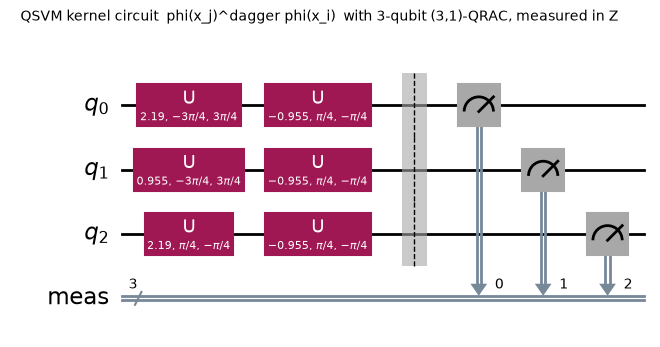

QRAC-3q(3,1): VQC circuit with 3 qubits | depth(decomposed)=20 | input parameters=9 | trainable weights=18


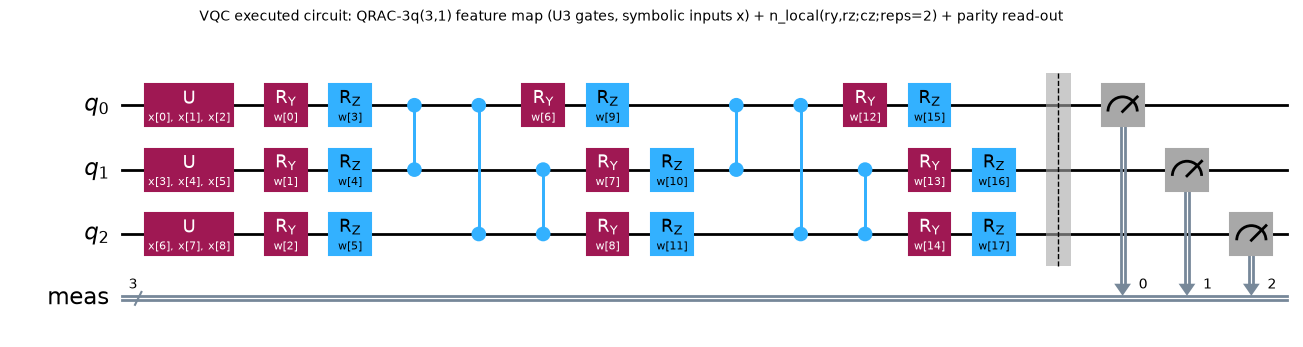

QRAC-2q(3,1): VQC circuit with 2 qubits | depth(decomposed)=13 | input parameters=9 | trainable weights=12


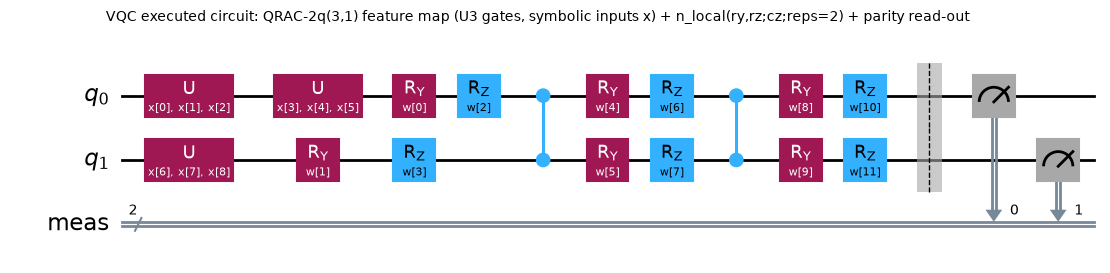

QRAC-2q(2,1): VQC circuit with 2 qubits | depth(decomposed)=14 | input parameters=12 | trainable weights=12


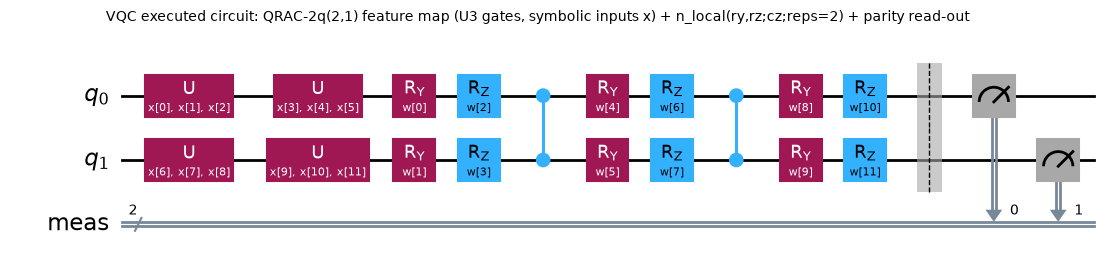

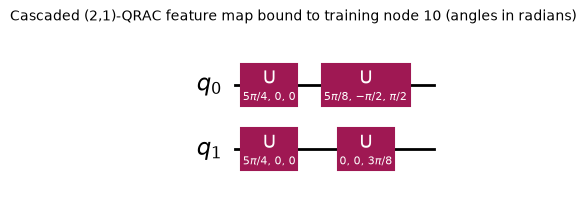

ZZ-VQC: qubits=7 | depth(decomposed)=101 | input parameters=7 | trainable weights=42 | entangling gates=126


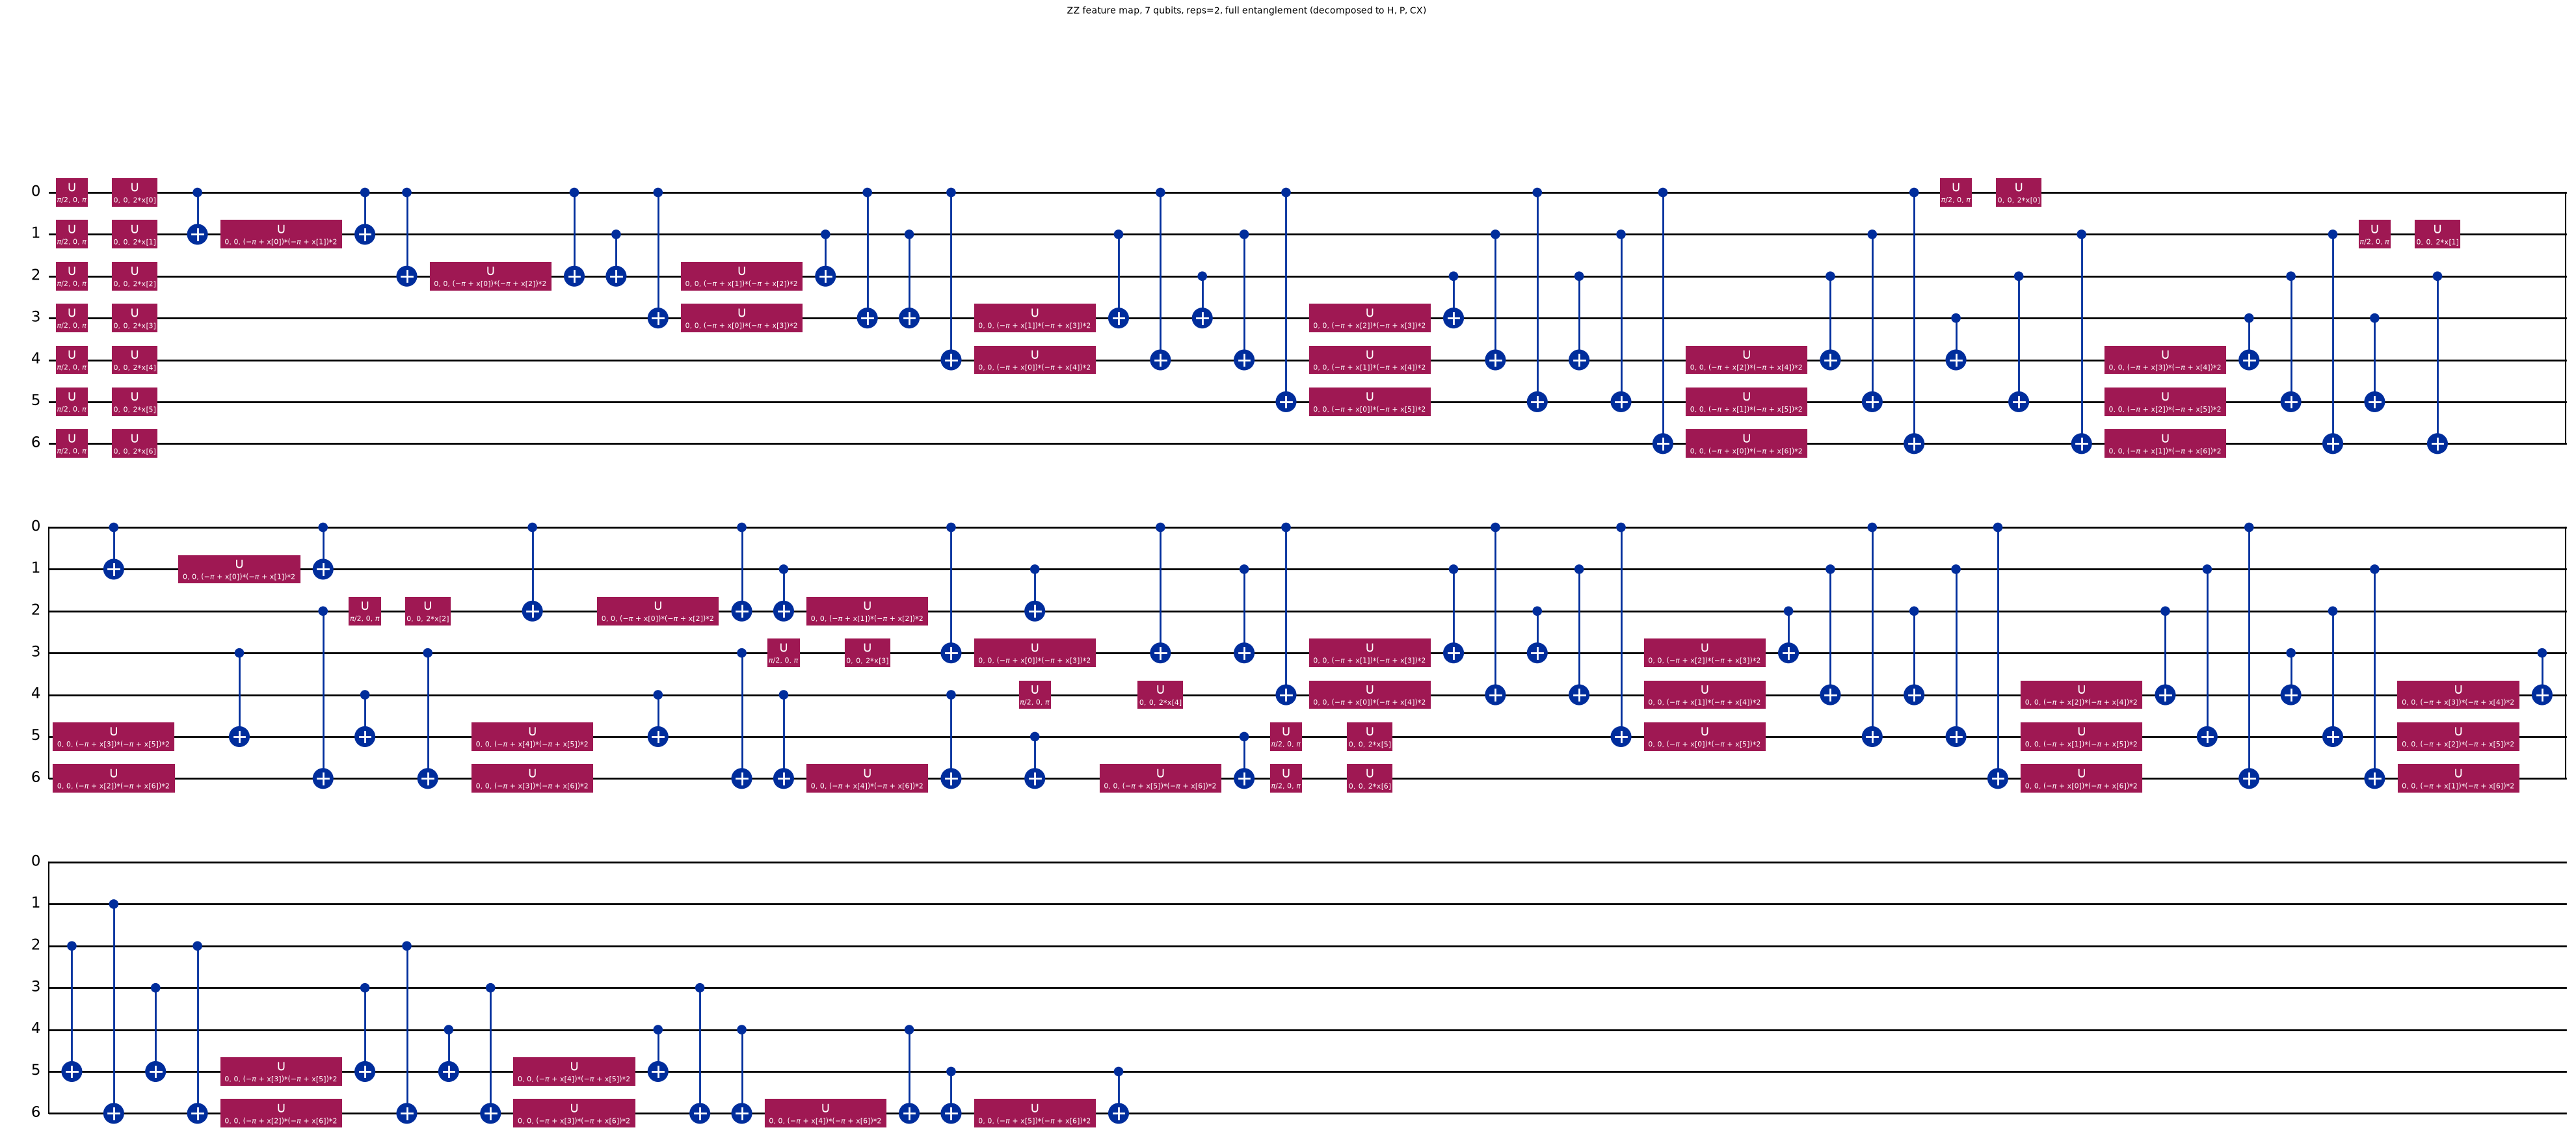

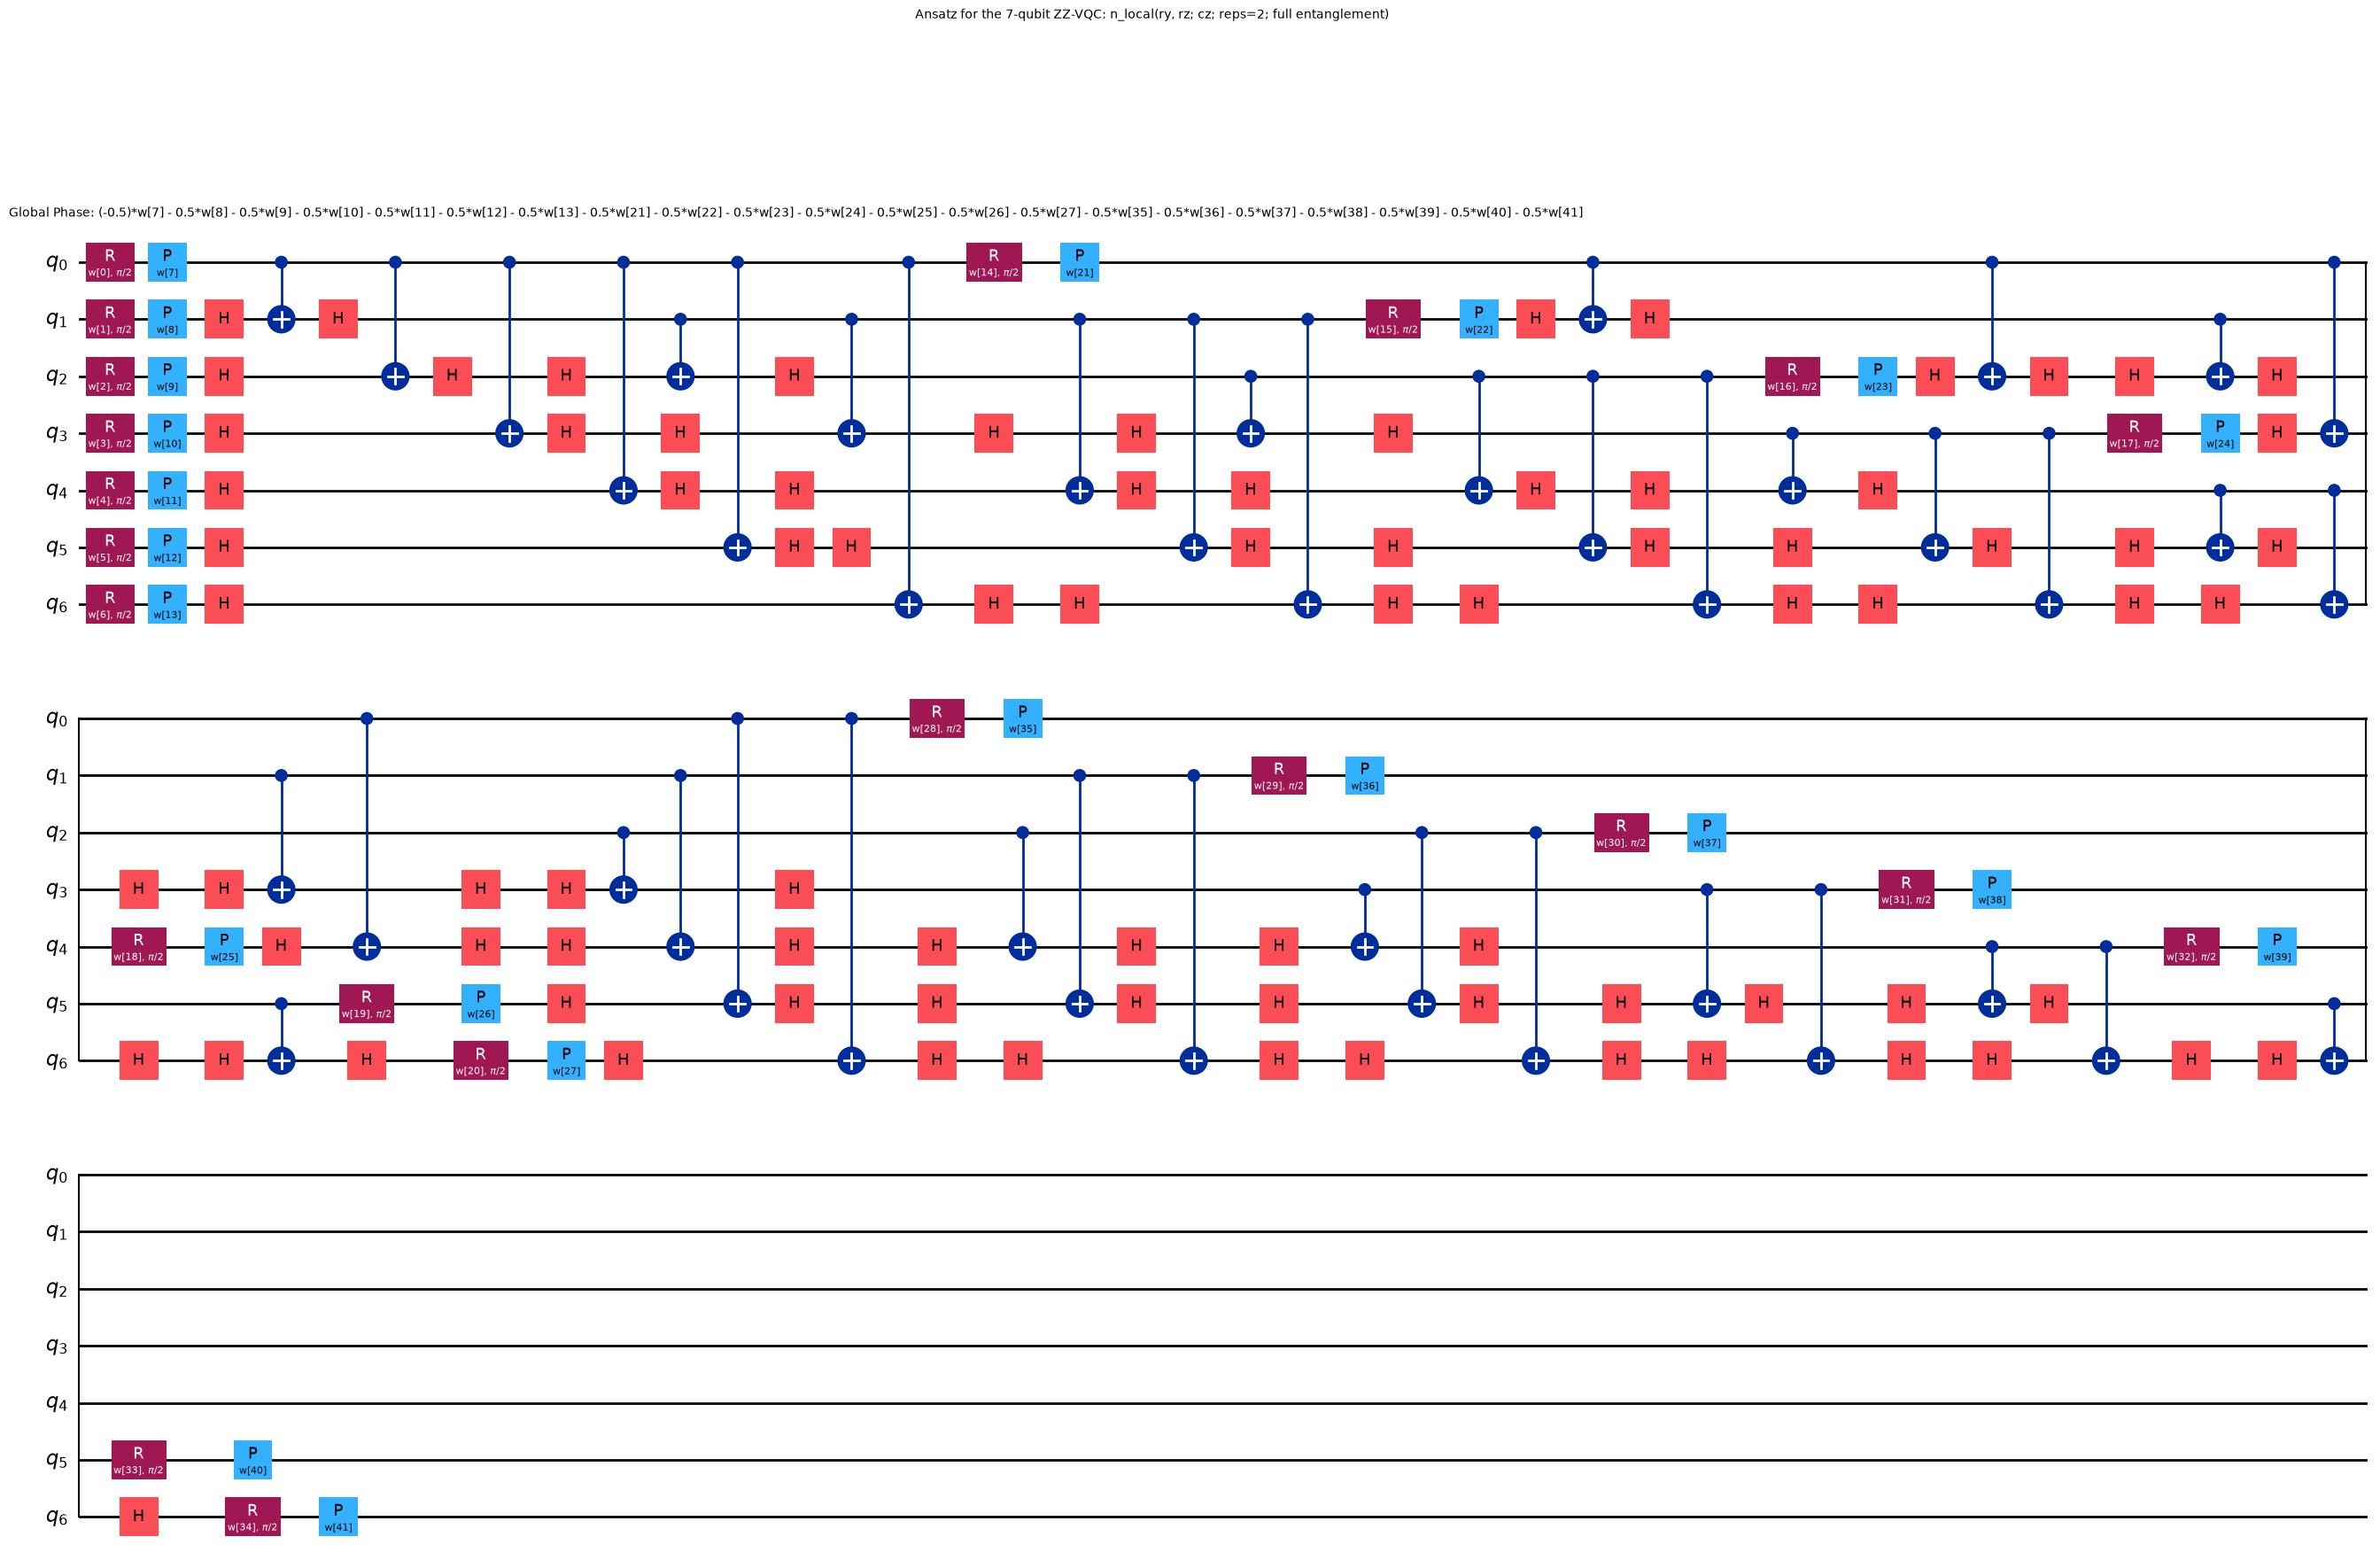

In [13]:
# ---- QSVM kernel circuit (compute-uncompute) and VQC circuits, drawn from the objects used below ----
e3 = ENC[("QRAC-3q(3,1)", "train")]
xa, xb = e3["tf"](X_tr[[0, 200]])
kc = e3["fm"].assign_parameters(xa).compose(e3["fm"].assign_parameters(xb).inverse()); kc.measure_all()
print(f"QSVM kernel circuit (3-qubit QRAC) for two training nodes: qubits={kc.num_qubits}, depth={kc.decompose().depth()}, trainable parameters=0 (kernel is non-parametric)")
show_circuit(kc, "QSVM kernel circuit  phi(x_j)^dagger phi(x_i)  with 3-qubit (3,1)-QRAC, measured in Z", fold=-1)

for name in ["QRAC-3q(3,1)", "QRAC-2q(3,1)", "QRAC-2q(2,1)"]:
    e = ENC[(name, "train")]; ans = make_ansatz(e["n"]); qnn_, qc_ = make_qnn(e["fm"], ans)
    c = qc_.copy(); c.measure_all()
    print(f"{name}: VQC circuit with {c.num_qubits} qubits | depth(decomposed)={qc_.decompose().decompose().depth()} | "
          f"input parameters={e['fm'].num_parameters} | trainable weights={ans.num_parameters}")
    show_circuit(c, f"VQC executed circuit: {name} feature map (U3 gates, symbolic inputs x) + n_local(ry,rz;cz;reps=2) + parity read-out", fold=40)

# one concrete (parameter-bound) example for the 2-qubit cascaded scheme
e = ENC[("QRAC-2q(2,1)", "train")]
ex = e["fm"].assign_parameters(e["tf"](X_tr[[10]])[0]); show_circuit(ex, "Cascaded (2,1)-QRAC feature map bound to training node 10 (angles in radians)")

# ZZ feature map (7 qubits): the circuit used by the ZZ-raw / ZZ-scaled encodings
ez = ENC[("ZZ-raw", "train")]; ansz = make_ansatz(7); _, qcz = make_qnn(ez["fm"], ansz)
print(f"ZZ-VQC: qubits=7 | depth(decomposed)={qcz.decompose().decompose().decompose().depth()} | input parameters=7 | trainable weights={ansz.num_parameters} | "
      f"entangling gates={qcz.decompose().decompose().decompose().count_ops().get('cx', 0)}")
show_circuit(ez["fm"].decompose(), "ZZ feature map, 7 qubits, reps=2, full entanglement (decomposed to H, P, CX)", fold=60)
show_circuit(ansz.decompose(), "Ansatz for the 7-qubit ZZ-VQC: n_local(ry, rz; cz; reps=2; full entanglement)", fold=40)

## 3. Evaluation helpers and the classical baselines

All metrics treat **phishing as the positive class**. For every model we store the predictions on the test set and compute
(i) metrics on the whole test set (1:10 imbalanced, the setting of the paper's Fig. 4-6) and (ii) metrics averaged over
`N_BAL_DRAWS` random balanced 150 + 150 subsets (the setting of Table 2). The classical baselines see the **same inputs** as
the quantum models: the 7 raw features (the authors' classical SVM / LGBM) and the 7 median bits that QRAC encodes.

In [14]:
RES = []          # one row per (model, encoding, seed)
PRED = {}         # predictions on the test set, keyed like RES rows

def metric_row(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=[0, 1], zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    return {"macro_f1": f1.mean(), "phish_f1": f1[1], "phish_prec": pr[1], "phish_rec": rc[1], "FN": fn, "FP": fp, "TP": tp, "TN": tn}

def register(model, enc, seed, pred, t_fit, t_pred, extra=None):
    pred = np.asarray(pred).astype(int)
    full = metric_row(y_te, pred)
    bal = pd.DataFrame([metric_row(y_te[i], pred[i]) for i in BAL_DRAWS]).mean()
    row = {"model": model, "encoding": enc, "seed": seed, "t_fit_s": t_fit, "t_pred_s": t_pred,
           **{f"full_{k}": v for k, v in full.items()}, **{f"bal_{k}": bal[k] for k in ("macro_f1", "phish_f1", "phish_prec", "phish_rec")}}
    if extra: row.update(extra)
    RES.append(row); PRED[(model, enc, seed)] = pred
    return row

def show(models=None, cols=("full_macro_f1", "full_phish_f1", "full_phish_rec", "full_FN", "full_FP", "bal_macro_f1", "bal_phish_f1", "bal_phish_rec", "t_fit_s")):
    df = pd.DataFrame(RES)
    if models is not None: df = df[df["model"].isin(models)]
    g = df.groupby(["model", "encoding"], sort=False)[list(cols)].agg(["mean", "std"]) if df["seed"].nunique() > 1 else df.set_index(["model", "encoding"])[list(cols)]
    return g.round(3)

# ---- classical baselines on identical inputs ----
BASE_MODELS = {"SVC-rbf": lambda: SVC(kernel="rbf"), LGBM_NAME: LGBM, "RandomForest": lambda: RandomForestClassifier(n_estimators=100, random_state=SEED)}
for model_name, mk in BASE_MODELS.items():
    for inp, (A, B) in {"raw-7": (X_tr, X_te), "bits-7": ((X_tr > THR_TRAIN).astype(float), (X_te > THR_TRAIN).astype(float))}.items():
        m = mk(); t0 = time.time(); m.fit(A, y_tr); t1 = time.time(); p = m.predict(B); t2 = time.time()
        register(model_name, inp, 0, p, t1 - t0, t2 - t1)
show()

full_macro_f1  full_phish_f1  full_phish_rec  full_FN  \
model        encoding                                                          
SVC-rbf      raw-7             0.728          0.500           0.441      559   
             bits-7            0.836          0.711           0.941       59   
LGBM         raw-7             0.821          0.687           0.968       32   
             bits-7            0.847          0.730           0.939       61   
RandomForest raw-7             0.793          0.642           0.969       31   
             bits-7            0.845          0.726           0.941       59   

                       full_FP  bal_macro_f1  bal_phish_f1  bal_phish_rec  \
model        encoding                                                       
SVC-rbf      raw-7         324         0.686         0.604          0.448   
             bits-7        706         0.937         0.937          0.943   
LGBM         raw-7         849         0.945         0.946          0.968   
             bits-7        632         0.939         0.939          0.941   
RandomForest raw-7        1048         0.936         0.938          0.971   
             bits-7        652         0.938         0.939          0.943   

                       t_fit_s  
model        encoding           
SVC-rbf      raw-7       0.008  
             bits-7      0.004  
LGBM         raw-7       0.055  
             bits-7      0.071  
RandomForest raw-7       0.851  
             bits-7      0.722

## 4. Fast, verified simulation of the circuits

Training a 7-qubit VQC with Qiskit's primitives costs about 30 ms per node and evaluation, i.e. many minutes per COBYLA run. The
circuits are small enough to simulate exactly in NumPy, so the notebook uses two exact simulation routines and **asserts that
they agree with Qiskit**:

* the **feature-map state** `|phi(x)>`: for QRAC circuits it is simply Qiskit's `Statevector` of the bound circuit (at most 128 distinct
  inputs); for the 7-qubit ZZ map a vectorised NumPy routine builds the state (`H^n`, then the diagonal phase
  `exp(i[sum_i 2 x_i b_i + sum_{i<j} 2 (pi - x_i)(pi - x_j)(b_i xor b_j)])`, repeated for `reps = 2`) and is compared with
  Qiskit's `Statevector` of `zz_feature_map` on random nodes;
* the **ansatz** unitary `U(w)`: `Operator` of the Qiskit `n_local` circuit with the weights bound; the VQC output is
  `<phi(x)| U^dagger (Z x ... x Z) U |phi(x)>`, compared with `EstimatorQNN` (the Qiskit machine-learning object) on random nodes.

In [15]:
HN = {}
def hadamard_n(n):
    if n not in HN:
        H1 = np.array([[1, 1], [1, -1]]) / np.sqrt(2); M = np.array([[1.0]])
        for _ in range(n): M = np.kron(M, H1)
        HN[n] = M
    return HN[n]

def zz_states(A, reps=2):
    """Exact states of zz_feature_map(n, reps, entanglement='full') for all rows of A (vectorised)."""
    A = np.asarray(A, float); N, n = A.shape; dim = 2 ** n
    b = ((np.arange(dim)[:, None] >> np.arange(n)) & 1).astype(float)              # b[:, i] = value of qubit i
    pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]
    xor = np.stack([np.abs(b[:, i] - b[:, j]) for i, j in pairs], axis=1)            # (dim, npairs)
    P = np.stack([(np.pi - A[:, i]) * (np.pi - A[:, j]) for i, j in pairs], axis=1)  # (N, npairs)
    phase = 2 * A @ b.T + 2 * P @ xor.T                                              # (N, dim)
    ph = np.exp(1j * phase); psi = np.full((N, dim), 1 / np.sqrt(dim), complex) * ph
    for _ in range(reps - 1):
        psi = (psi @ hadamard_n(n)) * ph
    return psi

def states_unique(e, A):
    """(states of the unique rows of A, index of every row into them)."""
    Au, inv = np.unique(np.round(np.asarray(A, float), 12), axis=0, return_inverse=True)
    if e["name"].startswith("ZZ"):
        S = zz_states(Au, reps=2)
    else:
        fmd = e["fm"].decompose(); S = np.array([Statevector(fmd.assign_parameters(a)).data for a in Au])
    return S, inv.ravel()

# ---- verification against Qiskit ----
for name in ("ZZ-raw", "ZZ-scaled"):
    e = ENC[(name, "train")]; A = e["tf"](X_tr[::37][:9]); S, inv = states_unique(e, A)
    for k, a in enumerate(A):
        ref = Statevector(e["fm"].assign_parameters(a)).data
        assert abs(abs(np.vdot(ref, S[inv[k]])) - 1) < 1e-9, (name, k)
    print(f"{name}: NumPy ZZ states equal Qiskit's Statevector (up to a global phase) on {len(A)} training nodes")

SIGNS = {n: np.array([1 - 2 * (bin(i).count("1") % 2) for i in range(2 ** n)], float) for n in (2, 3, 7)}
def ansatz_unitary(ans_dec, w): return Operator(ans_dec.assign_parameters(w)).data
def vqc_scores(Phi, U, n): return (np.abs(Phi @ U.T) ** 2) @ SIGNS[n]                  # <Z..Z> after the ansatz

for key, e in ENC.items():
    ans = make_ansatz(e["n"]); qnn_, _ = make_qnn(e["fm"], ans); w = np.random.default_rng(5).uniform(0, 2 * np.pi, ans.num_parameters)
    A = e["tf"](X_te[:6]); S, inv = states_unique(e, A)
    fast = vqc_scores(S[inv], ansatz_unitary(ans.decompose(), w), e["n"]); ref = qnn_.forward(A, w)[:, 0]
    assert np.allclose(fast, ref, atol=1e-8), (key, fast, ref)
print("fast VQC read-out == EstimatorQNN (Qiskit) for every encoding on 6 test nodes with random weights")

ZZ-raw: NumPy ZZ states equal Qiskit's Statevector (up to a global phase) on 9 training nodes


ZZ-scaled: NumPy ZZ states equal Qiskit's Statevector (up to a global phase) on 9 training nodes


fast VQC read-out == EstimatorQNN (Qiskit) for every encoding on 6 test nodes with random weights


## 5. QSVM with a quantum kernel (QSVM-qiskit)

The kernel of two nodes is the fidelity of their encoded states, `K(a, b) = |<phi(a)|phi(b)>|^2` (Sec. 3.4). We form the kernel
matrix with one matrix product of the exact states and train `SVC(kernel="precomputed", C=1)` on the 320 x 320 training kernel. The
authors' `QSVC` does the same with its default `C = 1`; the second cell proves it by comparing with Qiskit's own
`QSVC(quantum_kernel=FidelityStatevectorKernel(...))`.

In [16]:
def kernel_block(Sa, ia, Sb, ib):
    return (np.abs(Sa @ Sb.conj().T) ** 2)[np.ix_(ia, ib)]

def enc_label(name, mode):
    return name if mode == "train" else f"{name} [paper median]"

QSVM_STORE = {}
def run_qsvm(key, C=1.0):
    e = ENC[key]; t0 = time.time()
    A_tr_, A_te_ = e["tf"](X_tr), e["tf"](X_te)
    S_tr, i_tr = states_unique(e, A_tr_); S_te, i_te = states_unique(e, A_te_)
    K_tr = kernel_block(S_tr, i_tr, S_tr, i_tr); K_te = kernel_block(S_te, i_te, S_tr, i_tr)
    svc = SVC(kernel="precomputed", C=C).fit(K_tr, y_tr); t1 = time.time()
    p = svc.predict(K_te); t2 = time.time()
    QSVM_STORE[key] = {"svc": svc, "K_tr": K_tr, "K_te": K_te, "pred": p, "A_tr": A_tr_, "A_te": A_te_}
    register("QSVM", enc_label(*key), 0, p, t1 - t0, t2 - t1, {"n_support": len(svc.support_)})

for key in ENC:
    run_qsvm(key)
print("QSVM done for", len(ENC), "encodings")
show(["QSVM"], cols=("full_macro_f1", "full_phish_f1", "full_phish_rec", "full_FN", "full_FP", "bal_macro_f1", "bal_phish_f1", "bal_phish_rec", "n_support", "t_fit_s"))

QSVM done for 10 encodings


full_macro_f1  full_phish_f1  \
model encoding                                                            
QSVM  ZZ-raw                                       0.657          0.450   
      ZZ-scaled                                    0.653          0.444   
      QRAC-3q(3,1)                                 0.857          0.746   
      QRAC-2q(3,1)                                 0.821          0.686   
      QRAC-2q(2,1)                                 0.758          0.583   
      QRAC-2q(2,1) grouped                         0.761          0.591   
      QRAC-3q(3,1) [paper median]                  0.800          0.655   
      QRAC-2q(3,1) [paper median]                  0.733          0.552   
      QRAC-2q(2,1) [paper median]                  0.760          0.591   
      QRAC-2q(2,1) grouped [paper median]          0.733          0.552   

                                           full_phish_rec  full_FN  full_FP  \
model encoding                                                                
QSVM  ZZ-raw                                        0.981       19     2377   
      ZZ-scaled                                     0.977       23     2419   
      QRAC-3q(3,1)                                  0.942       58      583   
      QRAC-2q(3,1)                                  0.933       67      787   
      QRAC-2q(2,1)                                  0.893      107     1169   
      QRAC-2q(2,1) grouped                          0.943       57     1246   
      QRAC-3q(3,1) [paper median]                   0.978       22     1009   
      QRAC-2q(3,1) [paper median]                   0.980       20     1568   
      QRAC-2q(2,1) [paper median]                   0.966       34     1305   
      QRAC-2q(2,1) grouped [paper median]           0.980       20     1568   

                                           bal_macro_f1  bal_phish_f1  \
model encoding                                                          
QSVM  ZZ-raw                                      0.872         0.886   
      ZZ-scaled                                   0.870         0.884   
      QRAC-3q(3,1)                                0.942         0.942   
      QRAC-2q(3,1)                                0.928         0.928   
      QRAC-2q(2,1)                                0.893         0.894   
      QRAC-2q(2,1) grouped                        0.912         0.915   
      QRAC-3q(3,1) [paper median]                 0.940         0.942   
      QRAC-2q(3,1) [paper median]                 0.914         0.920   
      QRAC-2q(2,1) [paper median]                 0.921         0.925   
      QRAC-2q(2,1) grouped [paper median]         0.914         0.920   

                                           bal_phish_rec  n_support  t_fit_s  
model encoding                                                                
QSVM  ZZ-raw                                       0.981      238.0    0.594  
      ZZ-scaled                                    0.976      228.0    0.599  
      QRAC-3q(3,1)                                 0.944       80.0    0.917  
      QRAC-2q(3,1)                                 0.934       87.0    0.921  
      QRAC-2q(2,1)                                 0.897       82.0    1.029  
      QRAC-2q(2,1) grouped                         0.943       93.0    2.729  
      QRAC-3q(3,1) [paper median]                  0.977       52.0    1.892  
      QRAC-2q(3,1) [paper median]                  0.979       55.0    1.063  
      QRAC-2q(2,1) [paper median]                  0.964       67.0    1.325  
      QRAC-2q(2,1) grouped [paper median]          0.979       58.0    1.089

In [17]:
# ---- equivalence with Qiskit's own QSVC + FidelityStatevectorKernel (3-qubit QRAC; and a small ZZ-scaled check) ----
key = ("QRAC-3q(3,1)", "train"); e = ENC[key]; st = QSVM_STORE[key]
qk = FidelityStatevectorKernel(feature_map=e["fm"])
K_ref = qk.evaluate(st["A_tr"][:80])
assert np.allclose(K_ref, st["K_tr"][:80, :80], atol=1e-9), "hand-made kernel differs from FidelityStatevectorKernel"
qsvc = QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=e["fm"])).fit(st["A_tr"], y_tr)
p_ref = qsvc.predict(st["A_te"][:400])
assert (p_ref == st["pred"][:400]).all(), "QSVC predictions differ"
print("QRAC-3q: hand-made kernel == FidelityStatevectorKernel (80 x 80); QSVC predictions == SVC(precomputed) on 400 test nodes")
ez = ENC[("ZZ-scaled", "train")]; Az = ez["tf"](X_tr[:30]); Sz, iz = states_unique(ez, Az)
assert np.allclose(kernel_block(Sz, iz, Sz, iz), FidelityStatevectorKernel(feature_map=ez["fm"]).evaluate(Az), atol=1e-9)
print("ZZ-scaled: 30 x 30 kernel matches too.  Support vectors (QRAC-3q):", len(st["svc"].support_), "of 320")

QRAC-3q: hand-made kernel == FidelityStatevectorKernel (80 x 80); QSVC predictions == SVC(precomputed) on 400 test nodes


ZZ-scaled: 30 x 30 kernel matches too.  Support vectors (QRAC-3q): 80 of 320


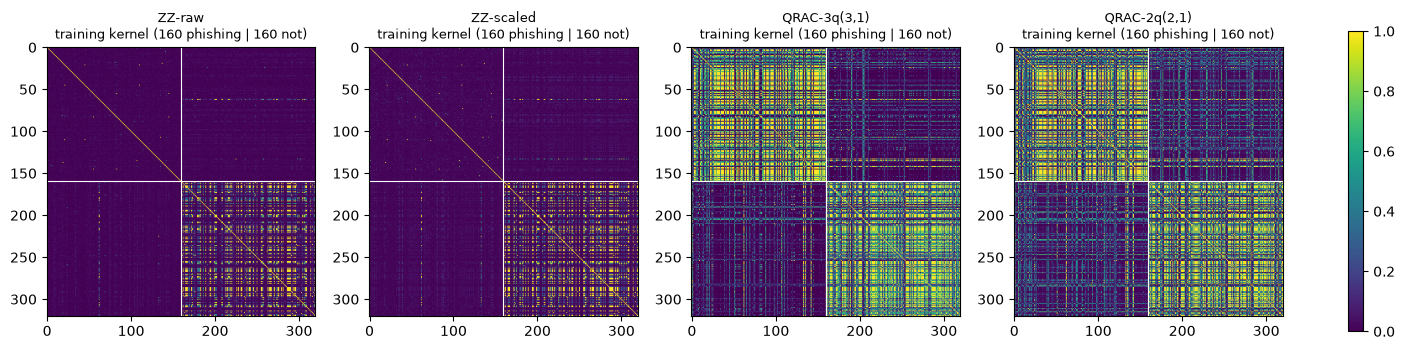

In [18]:
# ---- kernel matrices, sorted by class: what the SVM actually sees ----
fig, ax = plt.subplots(1, 4, figsize=(17, 3.9))
for a, key in zip(ax, [("ZZ-raw", "train"), ("ZZ-scaled", "train"), ("QRAC-3q(3,1)", "train"), ("QRAC-2q(2,1)", "train")]):
    im = a.imshow(QSVM_STORE[key]["K_tr"], vmin=0, vmax=1, cmap="viridis"); a.set_title(key[0] + "\ntraining kernel (160 phishing | 160 not)", fontsize=9)
    a.axhline(159.5, c="w", lw=0.8); a.axvline(159.5, c="w", lw=0.8); a.grid(False)
plt.colorbar(im, ax=ax, fraction=0.012); plt.show()

## 6. Variational Quantum Classifier (VQC)

The circuit is `feature map -> n_local(ry, rz; cz; reps=2)` and the prediction is the sign of `<Z x ... x Z>`: even parity of
the measured bit string means phishing (+1), odd parity not phishing (-1). Training minimises the mean squared error between that
expectation and the +-1 label with **COBYLA** (`maxiter = VQC_MAXITER`; the paper uses 100) on an exact statevector simulator, starting from random
weights drawn with the run's seed. Identical (input, label) pairs are merged with a weight, which gives exactly the same loss
as looping over all 320 nodes but is cheaper for QRAC, whose inputs take at most 128 values.

In [19]:
VQC_STORE = {}
def fit_vqc(e, Xs, ys_, seed, maxiter):
    ans = make_ansatz(e["n"]); ans_dec = ans.decompose()
    S, inv = states_unique(e, e["tf"](Xs))
    pairs, cnt = np.unique(np.c_[inv, ys_], axis=0, return_counts=True)
    Phi, yu, wu = S[pairs[:, 0]], 2.0 * pairs[:, 1] - 1, cnt / cnt.sum()
    hist = []
    def loss(w):
        out = vqc_scores(Phi, ansatz_unitary(ans_dec, w), e["n"]); l = float(np.sum(wu * (out - yu) ** 2)); hist.append(l); return l
    w0 = np.random.default_rng(seed).uniform(0, 2 * np.pi, ans.num_parameters)
    res = COBYLA(maxiter=maxiter).minimize(loss, w0)
    return {"ans": ans, "ans_dec": ans_dec, "w": np.asarray(res.x), "hist": hist}

def predict_vqc(v, e, X):
    S, inv = states_unique(e, e["tf"](X))
    s = vqc_scores(S, ansatz_unitary(v["ans_dec"], v["w"]), e["n"])[inv]
    return (s > 0).astype(int), s

for key, e in ENC.items():
    for seed in range(N_SEEDS):
        t0 = time.time(); v = fit_vqc(e, X_tr, y_tr, SEED + seed, VQC_MAXITER); t1 = time.time()
        p, s = predict_vqc(v, e, X_te); t2 = time.time()
        VQC_STORE[(key, seed)] = v
        register("VQC", enc_label(*key), seed, p, t1 - t0, t2 - t1, {"final_loss": v["hist"][-1]})
        print(f"VQC {enc_label(*key):28s} seed {seed}: train {t1 - t0:6.1f}s  predict {t2 - t1:5.1f}s  loss {v['hist'][0]:.3f} -> {v['hist'][-1]:.3f}  macro-F1(full test) {RES[-1]['full_macro_f1']:.3f}")
show(["VQC"], cols=("full_macro_f1", "full_phish_f1", "full_phish_rec", "full_FN", "full_FP", "bal_macro_f1", "bal_phish_f1", "bal_phish_rec", "final_loss", "t_fit_s"))

VQC ZZ-raw                       seed 0: train   27.7s  predict   0.7s  loss 0.987 -> 0.878  macro-F1(full test) 0.497


VQC ZZ-raw                       seed 1: train   18.9s  predict   0.6s  loss 1.019 -> 0.832  macro-F1(full test) 0.564


VQC ZZ-raw                       seed 2: train   22.9s  predict   0.8s  loss 1.022 -> 0.836  macro-F1(full test) 0.520


VQC ZZ-scaled                    seed 0: train   18.3s  predict   0.4s  loss 0.970 -> 0.904  macro-F1(full test) 0.491


VQC ZZ-scaled                    seed 1: train   19.8s  predict   0.6s  loss 1.044 -> 0.863  macro-F1(full test) 0.541


...

VQC QRAC-2q(2,1) [paper median]  seed 2: train    1.7s  predict   1.0s  loss 1.509 -> 0.317  macro-F1(full test) 0.783


VQC QRAC-2q(2,1) grouped [paper median] seed 0: train    1.6s  predict   1.1s  loss 0.691 -> 0.278  macro-F1(full test) 0.780


VQC QRAC-2q(2,1) grouped [paper median] seed 1: train    1.4s  predict   1.0s  loss 1.972 -> 0.260  macro-F1(full test) 0.790


VQC QRAC-2q(2,1) grouped [paper median] seed 2: train    1.8s  predict   1.0s  loss 1.439 -> 0.272  macro-F1(full test) 0.780


full_macro_f1        full_phish_f1  \
                                                   mean    std          mean   
model encoding                                                                 
VQC   ZZ-raw                                      0.527  0.034         0.241   
      ZZ-scaled                                   0.514  0.025         0.220   
      QRAC-3q(3,1)                                0.759  0.004         0.585   
      QRAC-2q(3,1)                                0.822  0.014         0.684   
      QRAC-2q(2,1)                                0.724  0.000         0.535   
      QRAC-2q(2,1) grouped                        0.807  0.059         0.665   
      QRAC-3q(3,1) [paper median]                 0.734  0.032         0.554   
      QRAC-2q(3,1) [paper median]                 0.728  0.027         0.546   
      QRAC-2q(2,1) [paper median]                 0.779  0.006         0.621   
      QRAC-2q(2,1) grouped [paper median]         0.783  0.006         0.628   

                                                 full_phish_rec         \
                                             std           mean    std   
model encoding                                                           
VQC   ZZ-raw                               0.033          0.515  0.008   
      ZZ-scaled                            0.025          0.475  0.023   
      QRAC-3q(3,1)                         0.006          0.903  0.027   
      QRAC-2q(3,1)                         0.023          0.844  0.003   
      QRAC-2q(2,1)                         0.000          0.927  0.002   
      QRAC-2q(2,1) grouped                 0.096          0.924  0.009   
      QRAC-3q(3,1) [paper median]          0.046          0.975  0.005   
      QRAC-2q(3,1) [paper median]          0.039          0.979  0.001   
      QRAC-2q(2,1) [paper median]          0.009          0.977  0.000   
      QRAC-2q(2,1) grouped [paper median]  0.010          0.975  0.000   

                                           full_FN           full_FP           \
                                              mean     std      mean      std   
model encoding                                                                  
VQC   ZZ-raw                               485.333   8.083  2808.333  515.039   
      ZZ-scaled                            525.333  23.180  2859.667  387.450   
      QRAC-3q(3,1)                          97.333  27.025  1182.000   58.924   
      QRAC-2q(3,1)                         156.000   3.464   624.667   86.933   
      QRAC-2q(2,1)                          73.333   1.528  1534.667    4.163   
      QRAC-2q(2,1) grouped                  76.000   8.888   895.667  394.933   
      QRAC-3q(3,1) [paper median]           25.000   4.583  1565.000  311.283   
      QRAC-2q(3,1) [paper median]           20.667   0.577  1620.333  267.948   
      QRAC-2q(2,1) [paper median]           23.000   0.000  1168.667   47.920   
      QRAC-2q(2,1) grouped [paper median]   25.000   0.000  1132.667   47.343   

                                          bal_macro_f1        bal_phish_f1  \
                                                  mean    std         mean   
model encoding                                                               
VQC   ZZ-raw                                     0.611  0.028        0.571   
      ZZ-scaled                                  0.588  0.025        0.541   
      QRAC-3q(3,1)                               0.893  0.009        0.895   
      QRAC-2q(3,1)                               0.894  0.001        0.889   
      QRAC-2q(2,1)                               0.888  0.000        0.893   
      QRAC-2q(2,1) grouped                       0.919  0.015        0.919   
      QRAC-3q(3,1) [paper median]                0.910  0.013        0.916   
      QRAC-2q(3,1) [paper median]                0.909  0.012        0.915   
      QRAC-2q(2,1) [paper median]                0.932  0.003        0.935   
      QRAC-2q(2,1) grouped [paper median]       

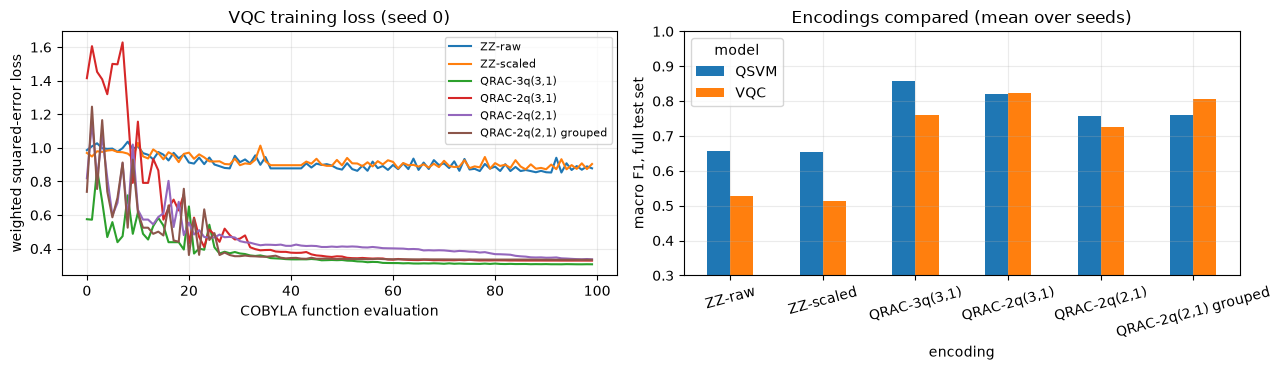

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for key in ENC:
    if key[1] != "train": continue
    ax[0].plot(VQC_STORE[(key, 0)]["hist"], label=key[0])
ax[0].set_xlabel("COBYLA function evaluation"); ax[0].set_ylabel("weighted squared-error loss"); ax[0].set_title("VQC training loss (seed 0)"); ax[0].legend(fontsize=8)
d = pd.DataFrame(RES); d = d[d["model"].isin(["QSVM", "VQC"]) & ~d["encoding"].str.contains("paper median")]
piv = d.groupby(["encoding", "model"], sort=False)["full_macro_f1"].mean().unstack().reindex(ENCODINGS)
piv.plot.bar(ax=ax[1], rot=15); ax[1].set_ylabel("macro F1, full test set"); ax[1].set_title("Encodings compared (mean over seeds)"); ax[1].set_ylim(0.3, 1)
plt.tight_layout(); plt.show()

## 7. Why QRAC helps (or not): classical models on the same bits

QRAC stores *binarised* features, so the whole difference between the QRAC rows and the ZZ rows may come from the binarisation
and the compact kernel rather than from anything quantum. The `bits-7` rows of Section 3 already answer this for classical
models: a plain RBF-SVM or gradient-boosting model on the 7 median bits uses exactly the information a QRAC circuit receives. The
cell below puts quantum and classical models trained on the same bits side by side.

In [21]:
d = pd.DataFrame(RES)
cmp_rows = d[(d["encoding"].isin(["bits-7", "QRAC-3q(3,1)", "QRAC-2q(3,1)", "QRAC-2q(2,1)"]))].groupby(["model", "encoding"], sort=False)[["full_macro_f1", "full_phish_rec", "full_FN", "bal_macro_f1"]].mean().round(3)
print("Models that see only the 7 median bits (QRAC circuits receive exactly this information):"); display(cmp_rows)

Models that see only the 7 median bits (QRAC circuits receive exactly this information):


full_macro_f1  full_phish_rec  full_FN  \
model        encoding                                               
SVC-rbf      bits-7                0.836           0.941   59.000   
LGBM         bits-7                0.847           0.939   61.000   
RandomForest bits-7                0.845           0.941   59.000   
QSVM         QRAC-3q(3,1)          0.857           0.942   58.000   
             QRAC-2q(3,1)          0.821           0.933   67.000   
             QRAC-2q(2,1)          0.758           0.893  107.000   
VQC          QRAC-3q(3,1)          0.759           0.903   97.333   
             QRAC-2q(3,1)          0.822           0.844  156.000   
             QRAC-2q(2,1)          0.724           0.927   73.333   

                           bal_macro_f1  
model        encoding                    
SVC-rbf      bits-7               0.937  
LGBM         bits-7               0.939  
RandomForest bits-7               0.938  
QSVM         QRAC-3q(3,1)         0.942  
             QRAC-2q(3,1)         0.928  
             QRAC-2q(2,1)         0.893  
VQC          QRAC-3q(3,1)         0.893  
             QRAC-2q(3,1)         0.894  
             QRAC-2q(2,1)         0.888

## 8. QSVM by annealing (QSVM-dwave)

The SVM dual with a kernel `K` is `min_lambda 1/2 lambda^T (K . y y^T) lambda - 1^T lambda`, `lambda >= 0` (Eq. 1). Each
multiplier is written with binary variables, `lambda_i = sum_k p_k b_ik` with the precision vector `p = [1, 2]`
(so `lambda_i` in {0,1,2,3}), which gives a QUBO with 2 x 320 = 640 binary variables. The paper sends it to a D-Wave hybrid
solver with an RBF kernel of `sigma = 150`; **no annealer is available here**, so the identical QUBO is solved with
`dwave.samplers.SimulatedAnnealingSampler`. (The QCE 2023 version of the work lists "classical annealing" and D-Wave with the
same score.) Prediction follows Eq. 2-3: `sign(sum_i lambda_i y_i K(x, x_i) + b)` with
`b = mean_i(y_i - sum_j lambda_j y_j K_ji)`. This is a QUBO / annealing method, **not a gate circuit**, so the circuit section above does not draw it.

In [22]:
from sklearn.metrics.pairwise import rbf_kernel

def qsvm_qubo(K, y, precision=QA_PRECISION):
    ys = 2.0 * y - 1; N = len(y); p = np.asarray(precision, float); nb = len(p)
    P = np.kron(np.eye(N), p[None, :])                       # lambda = P @ b, shape (N, N*nb)
    Qm = K * np.outer(ys, ys)
    H = P.T @ Qm @ P; h = -P.T @ np.ones(N)                  # E(b) = 1/2 b^T H b + h^T b, b binary
    nv = N * nb
    lin = {i: float(0.5 * H[i, i] + h[i]) for i in range(nv)}
    iu, ju = np.triu_indices(nv, 1)
    quad = {(int(i), int(j)): float(H[i, j]) for i, j in zip(iu, ju)}
    return dimod.BinaryQuadraticModel(lin, quad, 0.0, "BINARY"), P, H, h

gamma = 1.0 / (2.0 * SIGMA ** 2)                             # K = exp(-||x - x'||^2 / (2 sigma^2)), sigma = 150
Kq_tr = rbf_kernel(X_tr, X_tr, gamma=gamma); Kq_te = rbf_kernel(X_te, X_tr, gamma=gamma)
print(f"RBF kernel sigma={SIGMA:g}: training kernel entries in [{Kq_tr.min():.3f}, {Kq_tr.max():.3f}] (the paper chose sigma so that they lie in [0,1])")
t0 = time.time(); bqm, P, H, hvec = qsvm_qubo(Kq_tr, y_tr)
ss = SimulatedAnnealingSampler().sample(bqm, num_reads=QA_READS, num_sweeps=QA_SWEEPS, seed=SEED)
best = ss.first; bvec = np.array([best.sample[i] for i in range(len(bqm.variables))], float)
assert abs(best.energy - (0.5 * bvec @ H @ bvec + hvec @ bvec)) < 1e-6          # the BQM is the intended QUBO
lam = P @ bvec; ys = 2.0 * y_tr - 1
b_off = float(np.mean(ys - (lam * ys) @ Kq_tr))             # Eq. 3
t1 = time.time()
dec = (Kq_te @ (lam * ys)) + b_off; p_qa = (dec > 0).astype(int); t2 = time.time()
register("QSVM-anneal (SA)", f"RBF sigma={SIGMA:g}", 0, p_qa, t1 - t0, t2 - t1, {"qubo_energy": float(best.energy), "n_sv": int((lam > 0).sum())})
print(f"QUBO: {len(bqm.variables)} binary variables, {bqm.num_interactions} couplings | best energy {best.energy:.2f} over {QA_READS} reads "
      f"(worst {ss.record.energy.max():.2f}) | support vectors {(lam > 0).sum()} | multipliers {np.bincount(lam.astype(int))} | {t1 - t0:.1f}s")

# reference: the exact classical soft-margin SVM with the same kernel
t0 = time.time(); svm_ref = SVC(kernel="precomputed", C=float(sum(QA_PRECISION))).fit(Kq_tr, y_tr); t1 = time.time()
register("SVC (precomputed RBF sigma=150)", f"RBF sigma={SIGMA:g}", 0, svm_ref.predict(Kq_te), t1 - t0, 0.0)
show(["QSVM-anneal (SA)", "SVC (precomputed RBF sigma=150)"], cols=("full_macro_f1", "full_phish_f1", "full_phish_rec", "full_FN", "full_FP", "bal_macro_f1", "bal_phish_f1", "bal_phish_rec", "t_fit_s"))

RBF kernel sigma=150: training kernel entries in [0.000, 1.000] (the paper chose sigma so that they lie in [0,1])


QUBO: 640 binary variables, 204480 couplings | best energy -424.05 over 50 reads (worst -398.35) | support vectors 204 | multipliers [116  51  22 131] | 4.8s


,,full_macro_f1,full_phish_f1,full_phish_rec,full_FN,full_FP,bal_macro_f1,bal_phish_f1,bal_phish_rec,t_fit_s
model,encoding,,,,,,,,,
QSVM-anneal (SA),RBF sigma=150,0.758,0.561,0.568,432,457,0.762,0.719,0.591,4.763
SVC (precomputed RBF sigma=150),RBF sigma=150,0.761,0.570,0.626,374,569,0.787,0.755,0.646,0.007


## 9. Stacked ensembles of quantum and classical models

Following Fig. 3 and the authors' notebooks, the **base models** are trained on the 7 features, predict the labels of the training and
the test nodes, and those labels are *appended as extra features* before the **meta-classifier** is trained. The paper's best
pair, QSVM-qiskit + GCN, needs the whole 3-million-node graph (17 h of GCN training) and cannot be rebuilt here. We run the
three variants that the authors' notebooks implement with data we have: **QSVM + LGBM -> logistic regression**, **QSVM -> LGBM**
and **VQC -> LGBM**. Because the base labels on the *training* nodes are in-sample, we also report a leakage-free
variant (`oof`) where the training-time base labels come from 5-fold cross-validated predictions.

In [23]:
def lgbm_fit(A, y): return LGBM().fit(A, y)
SKF = lambda: StratifiedKFold(5, shuffle=True, random_state=SEED)

def qsvm_train_labels(key, oof=False):
    st = QSVM_STORE[key]
    if not oof: return st["svc"].predict(st["K_tr"])
    out = np.zeros(len(y_tr), int)
    for tr, va in SKF().split(X_tr, y_tr):
        out[va] = SVC(kernel="precomputed", C=1.0).fit(st["K_tr"][np.ix_(tr, tr)], y_tr[tr]).predict(st["K_tr"][np.ix_(va, tr)])
    return out

def vqc_train_labels(key, seed=0, oof=False):
    e = ENC[key]
    if not oof: return predict_vqc(VQC_STORE[(key, seed)], e, X_tr)[0]
    out = np.zeros(len(y_tr), int)
    for tr, va in SKF().split(X_tr, y_tr):
        out[va] = predict_vqc(fit_vqc(e, X_tr[tr], y_tr[tr], SEED + seed, VQC_MAXITER), e, X_tr[va])[0]
    return out

QK = ("QRAC-3q(3,1)", "train"); VK = ("QRAC-2q(3,1)", "train")
for oof in (False, True):
    tag = "oof" if oof else "in-sample"
    q_tr = qsvm_train_labels(QK, oof); q_te = QSVM_STORE[QK]["pred"]
    lg = lgbm_fit(X_tr, y_tr); l_te = lg.predict(X_te)
    if oof:
        l_tr = np.zeros(len(y_tr), int)
        for tr, va in SKF().split(X_tr, y_tr): l_tr[va] = lgbm_fit(X_tr[tr], y_tr[tr]).predict(X_tr[va])
    else:
        l_tr = lg.predict(X_tr)
    # (a) QSVM + LGBM -> logistic regression (authors' lgbm_qsvm_as_base_lr_meta notebook)
    t0 = time.time(); meta = LogisticRegression(max_iter=2000).fit(np.c_[X_tr, l_tr, q_tr], y_tr); t1 = time.time()
    register(f"Stack QSVM+{LGBM_NAME}->LR [{tag}]", "QRAC-3q(3,1) + raw-7", 0, meta.predict(np.c_[X_te, l_te, q_te]), t1 - t0, 0.0)
    # (b) QSVM -> LGBM meta
    meta = lgbm_fit(np.c_[X_tr, q_tr], y_tr)
    register(f"Stack QSVM->{LGBM_NAME} [{tag}]", "QRAC-3q(3,1) + raw-7", 0, meta.predict(np.c_[X_te, q_te]), 0.0, 0.0)
    # (c) VQC -> LGBM meta (authors' vqc_base_lgbm_meta notebook)
    v_tr = vqc_train_labels(VK, 0, oof); v_te = predict_vqc(VQC_STORE[(VK, 0)], ENC[VK], X_te)[0]
    meta = lgbm_fit(np.c_[X_tr, v_tr], y_tr)
    register(f"Stack VQC->{LGBM_NAME} [{tag}]", "QRAC-2q(3,1) + raw-7", 0, meta.predict(np.c_[X_te, v_te]), 0.0, 0.0)
show([m for m in pd.DataFrame(RES)["model"].unique() if m.startswith("Stack")] + ["QSVM", LGBM_NAME],
     cols=("full_macro_f1", "full_phish_f1", "full_phish_rec", "full_FN", "full_FP", "bal_macro_f1", "bal_phish_rec"))

full_macro_f1  \
model                           encoding                                             
LGBM                            raw-7                                        0.821   
                                bits-7                                       0.847   
QSVM                            ZZ-raw                                       0.657   
                                ZZ-scaled                                    0.653   
                                QRAC-3q(3,1)                                 0.857   
                                QRAC-2q(3,1)                                 0.821   
                                QRAC-2q(2,1)                                 0.758   
                                QRAC-2q(2,1) grouped                         0.761   
                                QRAC-3q(3,1) [paper median]                  0.800   
                                QRAC-2q(3,1) [paper median]                  0.733   
                                QRAC-2q(2,1) [paper median]                  0.760   
                                QRAC-2q(2,1) grouped [paper median]          0.733   
Stack QSVM+LGBM->LR [in-sample] QRAC-3q(3,1) + raw-7                         0.820   
Stack QSVM->LGBM [in-sample]    QRAC-3q(3,1) + raw-7                         0.813   
Stack VQC->LGBM [in-sample]     QRAC-2q(3,1) + raw-7                         0.810   
Stack QSVM+LGBM->LR [oof]       QRAC-3q(3,1) + raw-7                         0.849   
Stack QSVM->LGBM [oof]          QRAC-3q(3,1) + raw-7                         0.815   
Stack VQC->LGBM [oof]           QRAC-2q(3,1) + raw-7                         0.810   

                                                                     full_phish_f1  \
model                           encoding                                             
LGBM                            raw-7                                        0.687   
                                bits-7                                       0.730   
QSVM                            ZZ-raw                                       0.450   
                                ZZ-scaled                                    0.444   
                                QRAC-3q(3,1)                                 0.746   
                                QRAC-2q(3,1)                                 0.686   
                                QRAC-2q(2,1)                                 0.583   
                                QRAC-2q(2,1) grouped                         0.591   
                                QRAC-3q(3,1) [paper median]                  0.655   
                                QRAC-2q(3,1) [paper median]                  0.552   
                                QRAC-2q(2,1) [paper median]                  0.591   
                                QRAC-2q(2,1) grouped [paper median]          0.552   
Stack QSVM+LGBM->LR [in-sample] QRAC-3q(3,1) + raw-7                         0.686   
Stack QSVM->LGBM [in-sample]    QRAC-3q(3,1) + raw-7                         0.675   
Stack VQC->LGBM [in-sample]     QRAC-2q(3,1) + raw-7                         0.670   
Stack QSVM+LGBM->LR [oof]       QRAC-3q(3,1) + raw-7                         0.734   
Stack QSVM->LGBM [oof]          QRAC-3q(3,1) + raw-7                         0.678   
Stack VQC->LGBM [oof]           QRAC-2q(3,1) + raw-7                         0.669   

                                                                     full_phish_rec  \
model                           encoding                                              
LGBM                            raw-7                                         0.968   
                                bits-7                                        0.939   
QSVM                            ZZ-raw                                        0.981   
                                ZZ-scaled                                     0.977   
                                QRAC-3q(3,1)                                  0.942   
                  

## 10. A noisy-simulator stand-in for the IBM hardware runs

The paper executed the trained circuits on `ibm_kingston` (Heron) with **128 shots**, transpilation optimisation level 1, no error
mitigation, on a balanced test subset of 300 nodes (Table 2). A real device is not part of this notebook, but Qiskit ships the
calibration data of that machine as `FakeKingston`; `AerSimulator.from_backend` turns it into a noisy simulator (gate errors,
T1/T2 relaxation, readout errors, native gates, coupling map). We run the **same trained models** through it with the same shot
count, circuits transpiled with `optimization_level=1`:

* **VQC**: each test node's circuit (feature map + trained ansatz + measurements) is run for 128 shots; the label is the sign of the
  parity expectation estimated from the counts. Nodes with identical angle vectors share one executed circuit.
* **QSVM**: the kernel entries between the test nodes and the *support vectors only* are estimated as the frequency of the all-zeros
  outcome of the compute-uncompute circuit (128 shots), exactly the saving described in Sec. 5.3 of the paper; the SVM decision
  function is then evaluated classically with the trained dual coefficients.

This is a **stand-in**: calibration drift, crosstalk and queueing are not modelled, and the node subset differs from the paper's.
Real-device numbers therefore remain "cannot be checked".

In [24]:
os.environ.setdefault("QISKIT_PARALLEL", "FALSE")
from qiskit_ibm_runtime.fake_provider import FakeKingston
from qiskit_aer import AerSimulator
backend = FakeKingston(); sim = AerSimulator.from_backend(backend)
print("noisy simulator built from", backend.name, "with", backend.num_qubits, "qubits; native gates:", sorted(backend.operation_names))

h = HW_N_TEST // 2
HW_IDX = np.r_[BAL_DRAWS[0][:150][:h], BAL_DRAWS[0][150:][:h]]            # balanced subset of the test set
yhw, Xhw = y_te[HW_IDX], X_te[HW_IDX]

def run_counts(circs):
    tc = transpile(circs, backend, optimization_level=1, seed_transpiler=SEED)
    res = sim.run(tc, shots=HW_SHOTS, seed_simulator=SEED).result()
    return [res.get_counts(i) for i in range(len(circs))], tc

def hw_vqc(key, seed=0):
    e = ENC[key]; v = VQC_STORE[(key, seed)]
    _, qc = make_qnn(e["fm"], v["ans"])
    Au, inv = np.unique(np.round(e["tf"](Xhw), 12), axis=0, return_inverse=True); inv = inv.ravel()
    circs = []
    for a in Au:
        c = bind(qc, e["fm"], v["ans"], a, v["w"]); c.measure_all(); circs.append(c)
    cnts, tc = run_counts(circs)
    par = np.array([sum(n * (1 if bin(int(b, 2)).count("1") % 2 == 0 else -1) for b, n in c.items()) / HW_SHOTS for c in cnts])
    return (par[inv] > 0).astype(int), predict_vqc(v, e, Xhw)[0], tc[0]

def hw_qsvm(key):
    e = ENC[key]; st = QSVM_STORE[key]; svc = st["svc"]; sv = svc.support_
    A_sv = np.round(st["A_tr"][sv], 12); A_t = np.round(e["tf"](Xhw), 12)
    Au_t, inv_t = np.unique(A_t, axis=0, return_inverse=True); Au_s, inv_s = np.unique(A_sv, axis=0, return_inverse=True)
    circs = []
    for a in Au_t:
        for b in Au_s:
            c = e["fm"].assign_parameters(a).compose(e["fm"].assign_parameters(b).inverse()); c.measure_all(); circs.append(c)
    cnts, tc = run_counts(circs)
    Ku = np.array([c.get("0" * e["n"], 0) / HW_SHOTS for c in cnts]).reshape(len(Au_t), len(Au_s))
    Kfull = np.zeros((len(Xhw), len(st["K_tr"]))); Kfull[:, sv] = Ku[np.ix_(inv_t.ravel(), inv_s.ravel())]
    return svc.predict(Kfull), svc.predict(st["K_te"][HW_IDX]), tc[0]

HW_RESULTS = []; HW_CIRC = {}
HW_CASES = [("VQC", ("QRAC-3q(3,1)", "train")), ("VQC", ("QRAC-2q(3,1)", "train")), ("QSVM", ("QRAC-3q(3,1)", "train")), ("QSVM", ("QRAC-2q(2,1)", "train"))]
for model, key in HW_CASES:
    t0 = time.time()
    noisy, ideal, tcirc = hw_vqc(key) if model == "VQC" else hw_qsvm(key)
    HW_CIRC[(model, key[0])] = tcirc
    mi, mn = metric_row(yhw, ideal), metric_row(yhw, noisy)
    HW_RESULTS.append({"model": model, "encoding": key[0], "ideal macro F1": mi["macro_f1"], "noisy macro F1": mn["macro_f1"], "ideal phish F1": mi["phish_f1"],
                       "noisy phish F1": mn["phish_f1"], "ideal phish recall": mi["phish_rec"], "noisy phish recall": mn["phish_rec"],
                       "transpiled depth": tcirc.depth(), "2q gates": sum(tcirc.count_ops().get(g, 0) for g in ("cz", "cx", "ecr")), "seconds": time.time() - t0})
    print(f"{model:5s} {key[0]:14s} ideal {mi['macro_f1']:.3f} -> noisy {mn['macro_f1']:.3f}   ({time.time() - t0:.0f}s)")
display(pd.DataFrame(HW_RESULTS).round(3))

noisy simulator built from fake_kingston with 156 qubits; native gates: ['cz', 'delay', 'id', 'if_else', 'measure', 'measure_2', 'reset', 'rz', 'sx', 'x']


VQC   QRAC-3q(3,1)   ideal 0.877 -> noisy 0.883   (16s)


VQC   QRAC-2q(3,1)   ideal 0.896 -> noisy 0.897   (10s)


QSVM  QRAC-3q(3,1)   ideal 0.947 -> noisy 0.943   (54s)


QSVM  QRAC-2q(2,1)   ideal 0.903 -> noisy 0.920   (39s)


,model,encoding,ideal macro F1,noisy macro F1,ideal phish F1,noisy phish F1,ideal phish recall,noisy phish recall,transpiled depth,2q gates,seconds
0,VQC,"QRAC-3q(3,1)",0.877,0.883,0.876,0.882,0.873,0.873,36,12,15.621
1,VQC,"QRAC-2q(3,1)",0.896,0.897,0.892,0.893,0.853,0.867,16,2,9.526
2,QSVM,"QRAC-3q(3,1)",0.947,0.943,0.947,0.944,0.960,0.953,1,0,53.977
3,QSVM,"QRAC-2q(2,1)",0.903,0.920,0.906,0.923,0.933,0.953,1,0,38.726


## 11. Side-by-side comparison with the paper

Verdict rule (as for every notebook in this repository): a number is **reproduced** when it lies within 0.02 F1 (2 points) of the
paper's value, **exceeded** / **not reached** when it is more than 0.02 above / below, and **cannot be checked** when the paper
gives no value or needs hardware / data that are not available. Table 2 of the paper uses a balanced 300-node test subset, so
the notebook's `bal_*` columns (mean over `N_BAL_DRAWS` random 150 + 150 subsets of the test set) are the matching quantities;
`draw std` shows how much a single 300-node draw fluctuates (the paper's single subset carries that uncertainty, about +-0.02), and
`seed std` how much the VQC varies with its random start.

In [25]:
D = pd.DataFrame(RES)
def getv(model, enc, col):
    s = D[(D["model"] == model) & (D["encoding"] == enc)][col]
    return float(s.mean()) if len(s) else np.nan
def getsd(model, enc, col):
    s = D[(D["model"] == model) & (D["encoding"] == enc)][col]
    return float(s.std()) if len(s) > 1 else np.nan
def draw_sd(model, enc, col="macro_f1"):
    k = (model, enc, 0)
    return float(np.std([metric_row(y_te[i], PRED[k][i])[col] for i in BAL_DRAWS])) if k in PRED else np.nan
def verdict(paper, mine, tol=0.02):
    if np.isnan(mine): return "cannot be checked"
    return "reproduced" if abs(mine - paper) <= tol else (f"exceeded (+{mine - paper:.2f})" if mine > paper else f"not reached ({mine - paper:+.2f})")

T2 = [  # paper Table 2 simulator rows: (model, encoding in this notebook, macro F1, phishing F1, phishing recall, label)
    ("VQC", "QRAC-3q(3,1)", 0.78, 0.82, 0.96, "VQC QRAC(3 qubits)"),
    ("VQC", "QRAC-2q(3,1)", 0.89, 0.90, 0.96, "VQC QRAC(2 qubits) = concatenated (3,1)"),
    ("VQC", "QRAC-2q(2,1)", 0.89, 0.90, 0.96, "VQC QRAC(2 qubits) = cascaded (2,1)"),
    ("VQC", "QRAC-2q(2,1) grouped", 0.89, 0.90, 0.96, "VQC QRAC(2 qubits) = cascaded (2,1), grouped sensitivity variant"),
    ("QSVM", "QRAC-3q(3,1)", 0.94, 0.94, 0.95, "QSVM QRAC(3 qubits)"),
    ("QSVM", "QRAC-2q(2,1)", 0.92, 0.92, 0.96, "QSVM QRAC(2 qubits) = cascaded (2,1)"),
    ("QSVM", "QRAC-2q(2,1) grouped", 0.92, 0.92, 0.96, "QSVM QRAC(2 qubits) = cascaded (2,1), grouped sensitivity variant"),
    ("QSVM", "QRAC-2q(3,1)", 0.92, 0.92, 0.96, "QSVM QRAC(2 qubits) = concatenated (3,1)"),
    # ZZ rows come from the 2023 predecessor paper (Tables II and III, same data, 300 + 300 setting); the 2026 paper gives no ZZ table
    ("VQC", "ZZ-raw", 0.67, 0.63, 0.55, "VQC ZZ feature map [QCE 2023 Table II]"),
    ("QSVM", "ZZ-raw", 0.90, 0.90, 0.93, "QSVM ZZ feature map [QCE 2023 Table III]")]
rows = []
for model, enc, mf, pf, pr, label in T2:
    for metric, col, pv in (("macro F1", "bal_macro_f1", mf), ("phishing F1", "bal_phish_f1", pf), ("phishing recall", "bal_phish_rec", pr)):
        mv = getv(model, enc, col)
        rows.append({"claim": f"C1 {label}", "metric": metric, "paper": pv, "notebook": round(mv, 3),
                     "draw std": round(draw_sd(model, enc, col.replace("bal_", "").replace("phish_rec", "phish_rec")), 3) if metric == "macro F1" else "",
                     "seed std": round(getsd(model, enc, col), 3) if metric == "macro F1" and N_SEEDS > 1 and model == "VQC" else "",
                     "verdict": verdict(pv, mv)})
C1 = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120, "display.width", 250, "display.max_rows", 200)
display(C1)

,claim,metric,paper,notebook,draw std,seed std,verdict
0,C1 VQC QRAC(3 qubits),macro F1,0.78,0.893,0.024,0.009,exceeded (+0.11)
1,C1 VQC QRAC(3 qubits),phishing F1,0.82,0.895,,,exceeded (+0.07)
2,C1 VQC QRAC(3 qubits),phishing recall,0.96,0.906,,,not reached (-0.05)
3,"C1 VQC QRAC(2 qubits) = concatenated (3,1)",macro F1,0.89,0.894,0.02,0.001,reproduced
4,"C1 VQC QRAC(2 qubits) = concatenated (3,1)",phishing F1,0.90,0.889,,,reproduced
5,"C1 VQC QRAC(2 qubits) = concatenated (3,1)",phishing recall,0.96,0.851,,,not reached (-0.11)
6,"C1 VQC QRAC(2 qubits) = cascaded (2,1)",macro F1,0.89,0.888,0.016,0.0,reproduced
7,"C1 VQC QRAC(2 qubits) = cascaded (2,1)",phishing F1,0.90,0.893,,,reproduced
8,"C1 VQC QRAC(2 qubits) = cascaded (2,1)",phishing recall,0.96,0.927,,,not reached (-0.03)
9,"C1 VQC QRAC(2 qubits) = cascaded (2,1), grouped sensitivity variant",macro F1,0.89,0.919,0.013,0.015,exceeded (+0.03)


In [26]:
rows = []
# C2: relative gain of QRAC over the ZZ feature map in macro F1. The abstract's "13 % / 3 %" are relative gains of the Table-2 style
# (balanced 300-node) macro F1 (QCE 2023: VQC 0.67 -> 0.76, QSVM 0.90 -> 0.93); we compute them on the balanced draws and on the full test set.
for model, paper_gain in (("VQC", 13.0), ("QSVM", 3.0)):
    for col, tag in (("bal_macro_f1", "balanced 300-node draws"), ("full_macro_f1", "full imbalanced test set")):
        qr = {q: getv(model, q, col) for q in ("QRAC-3q(3,1)", "QRAC-2q(3,1)", "QRAC-2q(2,1)")}
        bq = max(qr, key=qr.get)
        for z in ("ZZ-raw", "ZZ-scaled"):
            zz = getv(model, z, col); gain = 100 * (qr[bq] - zz) / zz
            v = "reproduced" if abs(gain - paper_gain) <= 3 else (f"exceeded (+{gain - paper_gain:.1f} pts)" if gain > paper_gain else f"not reached ({gain - paper_gain:+.1f} pts)")
            rows.append({"claim": f"C2 {model}: best QRAC ({bq}) vs {z}, macro F1, {tag}", "paper": f"+{paper_gain:.0f} %", "notebook": f"{gain:+.1f} % ({qr[bq]:.3f} vs {zz:.3f})",
                         "verdict": v + ("; direction (QRAC > ZZ) reproduced" if gain > 0 else "; direction NOT reproduced")})
# C3: 2-qubit cascaded (2,1) matches the 3-qubit (3,1)-QRAC
for model in ("QSVM", "VQC"):
    for enc2 in ("QRAC-2q(2,1)", "QRAC-2q(2,1) grouped"):
        for col, tag in (("bal_macro_f1", "balanced draws"), ("full_macro_f1", "full test")):
            a, b = getv(model, enc2, col), getv(model, "QRAC-3q(3,1)", col)
            rows.append({"claim": f"C3 {model}: {enc2} vs 3q (3,1), macro F1, {tag}", "paper": "closely matches", "notebook": f"{a:.3f} vs {b:.3f} (diff {a - b:+.3f})",
                         "verdict": "reproduced" if abs(a - b) <= 0.02 else ("2q better by more than 0.02" if a > b else "2q worse by more than 0.02")})
# C4: fewest false negatives among the individual models (GCN not run)
ind = D[~D["model"].str.startswith("Stack") & ~D["model"].str.startswith("SVC (pre") & ~D["encoding"].str.contains("paper median")]
fn = ind.groupby(["model", "encoding"], sort=False)["full_FN"].mean().sort_values()
fp = ind.groupby(["model", "encoding"], sort=False)["full_FP"].mean()
q3 = getv("QSVM", "QRAC-3q(3,1)", "full_FN")
top3 = "; ".join(f"{m}/{e}: FN {v:.0f} (FP {fp[(m, e)]:.0f})" for (m, e), v in fn.head(4).items())
qsvm_qrac_best = fn.loc[[i for i in fn.index if i[0] == "QSVM" and i[1].startswith("QRAC")]].min()
rows.append({"claim": "C4 fewest false negatives among individual models (GCN not run)", "paper": "QSVM-qiskit (QRAC) lowest FN, highest TP",
             "notebook": f"lowest FN: {top3}. QSVM-QRAC-3q FN {q3:.0f}",
             "verdict": "reproduced" if qsvm_qrac_best <= fn.min() else "not reached: a classical model (or ZZ-QSVM at the price of many FP) has fewer FN than QSVM-QRAC"})
# C5: stacking vs the QSVM alone (analogue of QSVM + GCN; the GCN itself cannot be run)
q_fn, q_fp = getv("QSVM", "QRAC-3q(3,1)", "full_FN"), getv("QSVM", "QRAC-3q(3,1)", "full_FP")
for m in [m for m in D["model"].unique() if m.startswith("Stack")]:
    r = D[D["model"] == m].iloc[0]
    rows.append({"claim": f"C5 {m}", "paper": "stacking QSVM with a complementary model lowers FN / raises recall",
                 "notebook": f"FN {r['full_FN']:.0f} (QSVM alone {q_fn:.0f}), FP {r['full_FP']:.0f} (QSVM alone {q_fp:.0f}), recall {r['full_phish_rec']:.3f}, macro F1 {r['full_macro_f1']:.3f}",
                 "verdict": ("fewer FN than QSVM alone" if r["full_FN"] < q_fn else "not fewer FN than QSVM alone") + (", more FP" if r["full_FP"] > q_fp else ", not more FP")})
rows.append({"claim": "C5 QSVM + GCN (the paper's best pair) and the GCN's own scores", "paper": "GCN best overall; QSVM+GCN least FN", "notebook": "GCN needs the full 3 M-node graph (not public)", "verdict": "cannot be checked"})
# C6: annealing QSVM (QCE 2023 Table III, same data, 300 + 300 setting): macro F1 0.78, phishing F1 0.74, phishing recall 0.63
for metric, col, pv in (("macro F1", "bal_macro_f1", 0.78), ("phishing F1", "bal_phish_f1", 0.74), ("phishing recall", "bal_phish_rec", 0.63)):
    mv = getv("QSVM-anneal (SA)", f"RBF sigma={SIGMA:g}", col)
    rows.append({"claim": f"C6 QSVM-dwave, {metric} (SA stand-in, balanced draws)", "paper": pv, "notebook": round(mv, 3), "verdict": verdict(pv, mv)})
mvr = getv("QSVM-anneal (SA)", f"RBF sigma={SIGMA:g}", "full_macro_f1")
rows.append({"claim": "C6 QSVM-dwave on a real D-Wave annealer", "paper": "same score as classical annealing", "notebook": f"SA stand-in only (full-test macro F1 {mvr:.3f})", "verdict": "cannot be checked (no annealer)"})
# C7: hardware
hw = pd.DataFrame(HW_RESULTS)
paper_hw = {("VQC", "QRAC-3q(3,1)"): (0.78, 0.75), ("VQC", "QRAC-2q(3,1)"): (0.89, 0.61), ("QSVM", "QRAC-3q(3,1)"): (0.94, 0.91), ("QSVM", "QRAC-2q(2,1)"): (0.92, 0.90)}
for _, r in hw.iterrows():
    ps, ph = paper_hw[(r["model"], r["encoding"])]
    rows.append({"claim": f"C7 {r['model']} {r['encoding']} on ibm_kingston (noisy-simulator stand-in, {HW_N_TEST} nodes, {HW_SHOTS} shots)", "paper": f"simulator {ps:.2f} -> hardware {ph:.2f}",
                 "notebook": f"ideal {r['ideal macro F1']:.2f} -> noisy-sim {r['noisy macro F1']:.2f}", "verdict": "cannot be checked (hardware); stand-in shown for orientation"})
# C8: dataset statistics
for cls, idx in (("phishing", 1), ("non-phishing", 0)):
    mv = full_te[lab == idx].mean().values; pv = np.array(PAPER_T1[f"{cls} mean"]); rel = np.abs(mv - pv) / pv
    rows.append({"claim": f"C8 Table 1, {cls} feature means (11,000-node test file vs the paper's full crawl subset)", "paper": "see Section 'Dataset Exploration'", "notebook": f"max relative difference {rel.max() * 100:.0f} % (feature {FEATURES[rel.argmax()]})",
                 "verdict": "reproduced (within 10 %)" if rel.max() < 0.10 else "differs"})
CMP = pd.DataFrame(rows)
display(CMP)

,claim,paper,notebook,verdict
0,"C2 VQC: best QRAC (QRAC-2q(3,1)) vs ZZ-raw, macro F1, balanced 300-node draws",+13 %,+46.4 % (0.894 vs 0.611),exceeded (+33.4 pts); direction (QRAC > ZZ) reproduced
1,"C2 VQC: best QRAC (QRAC-2q(3,1)) vs ZZ-scaled, macro F1, balanced 300-node draws",+13 %,+51.9 % (0.894 vs 0.588),exceeded (+38.9 pts); direction (QRAC > ZZ) reproduced
2,"C2 VQC: best QRAC (QRAC-2q(3,1)) vs ZZ-raw, macro F1, full imbalanced test set",+13 %,+56.1 % (0.822 vs 0.527),exceeded (+43.1 pts); direction (QRAC > ZZ) reproduced
3,"C2 VQC: best QRAC (QRAC-2q(3,1)) vs ZZ-scaled, macro F1, full imbalanced test set",+13 %,+59.9 % (0.822 vs 0.514),exceeded (+46.9 pts); direction (QRAC > ZZ) reproduced
4,"C2 QSVM: best QRAC (QRAC-3q(3,1)) vs ZZ-raw, macro F1, balanced 300-node draws",+3 %,+8.0 % (0.942 vs 0.872),exceeded (+5.0 pts); direction (QRAC > ZZ) reproduced
5,"C2 QSVM: best QRAC (QRAC-3q(3,1)) vs ZZ-scaled, macro F1, balanced 300-node draws",+3 %,+8.3 % (0.942 vs 0.870),exceeded (+5.3 pts); direction (QRAC > ZZ) reproduced
6,"C2 QSVM: best QRAC (QRAC-3q(3,1)) vs ZZ-raw, macro F1, full imbalanced test set",+3 %,+30.3 % (0.857 vs 0.657),exceeded (+27.3 pts); direction (QRAC > ZZ) reproduced
7,"C2 QSVM: best QRAC (QRAC-3q(3,1)) vs ZZ-scaled, macro F1, full imbalanced test set",+3 %,+31.2 % (0.857 vs 0.653),exceeded (+28.2 pts); direction (QRAC > ZZ) reproduced
8,"C3 QSVM: QRAC-2q(2,1) vs 3q (3,1), macro F1, balanced draws",closely matches,0.893 vs 0.942 (diff -0.049),2q worse by more than 0.02
9,"C3 QSVM: QRAC-2q(2,1) vs 3q (3,1), macro F1, full test",closely matches,0.758 vs 0.857 (diff -0.099),2q worse by more than 0.02


full_macro_f1  full_phish_f1  full_phish_rec  full_FN   full_FP  bal_macro_f1  bal_phish_f1  bal_phish_rec  t_fit_s  t_pred_s
model                           encoding                                                                                                                                                          
SVC-rbf                         raw-7                                        0.728          0.500           0.441  559.000   324.000         0.686         0.604          0.448    0.008     0.816
                                bits-7                                       0.836          0.711           0.941   59.000   706.000         0.937         0.937          0.943    0.004     0.144
LGBM                            raw-7                                        0.821          0.687           0.968   32.000   849.000         0.945         0.946          0.968    0.055     0.131
                                bits-7                                       0.847          0.730           0.939   61.000   632.000         0.939         0.939          0.941    0.071     0.154
RandomForest                    raw-7                                        0.793          0.642           0.969   31.000  1048.000         0.936         0.938          0.971    0.851     0.151
                                bits-7                                       0.845          0.726           0.941   59.000   652.000         0.938         0.939          0.943    0.722     0.232
QSVM                            ZZ-raw                                       0.657          0.450           0.981   19.000  2377.000         0.872         0.886          0.981    0.594     0.087
                                ZZ-scaled                                    0.653          0.444           0.977   23.000  2419.000         0.870         0.884          0.976    0.599     0.082
                                QRAC-3q(3,1)                                 0.857          0.746           0.942   58.000   583.000         0.942         0.942          0.944    0.917     0.076
                                QRAC-2q(3,1)                                 0.821          0.686           0.933   67.000   787.000         0.928         0.928          0.934    0.921     0.059
                                QRAC-2q(2,1)                                 0.758          0.583           0.893  107.000  1169.000         0.893         0.894          0.897    1.029     0.059
                                QRAC-2q(2,1) grouped                         0.761          0.591           0.943   57.000  1246.000         0.912         0.915          0.943    2.729     0.083
                                QRAC-3q(3,1) [paper median]                  0.800          0.655           0.978   22.000  1009.000         0.940         0.942          0.977    1.892     0.070
                                QRAC-2q(3,1) [paper median]                  0.733          0.552           0.980   20.000  1568.000         0.914         0.920          0.979    1.063     0.069
                                QRAC-2q(2,1) [paper median]                  0.760          0.591           0.966   34.000  1305.000         0.921         0.925          0.964    1.325     0.071
                                QRAC-2q(2,1) grouped [paper median]          0.733          0.552           0.980   20.000  1568.000         0.914         0.920          0.979    1.089     0.068
VQC                             ZZ-raw                                       0.527          0.241           0.515  485.333  2808.333         0.611         0.571          0.512   23.153     0.708
                                ZZ-scaled                                    0.514          0.220           0.475  525.333  2859.667         0.588         0.541          0.478   21.338     0.564
                                QRAC-3q(3,1)                                 0.759          0.585           0.903   97.333  1182.000         0.893         0.895         

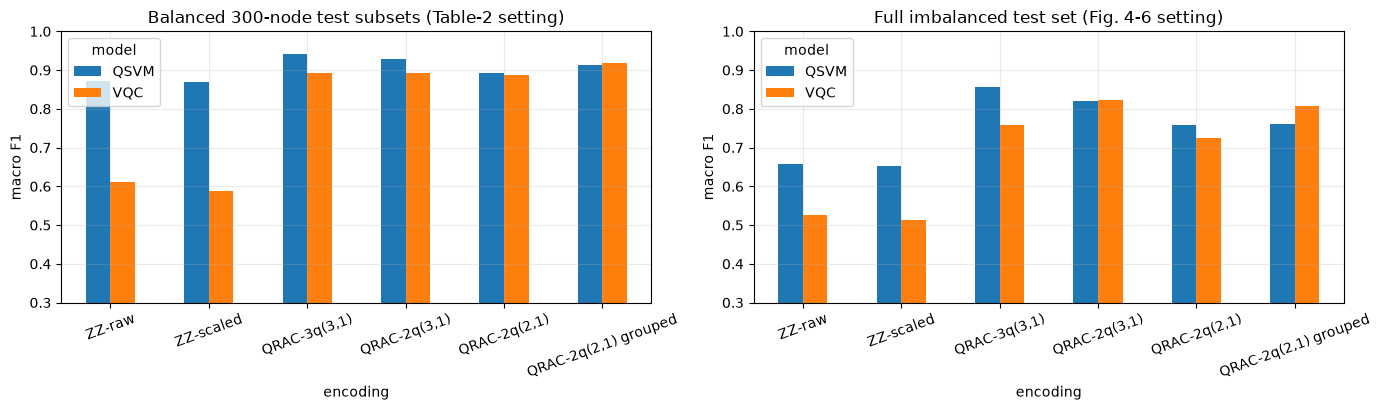

In [27]:
# ---- full results table (all models, mean over seeds) and the headline figure ----
cols = ["full_macro_f1", "full_phish_f1", "full_phish_rec", "full_FN", "full_FP", "bal_macro_f1", "bal_phish_f1", "bal_phish_rec", "t_fit_s", "t_pred_s"]
final = D.groupby(["model", "encoding"], sort=False)[cols].mean().round(3)
display(final)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
sub = D[D["model"].isin(["QSVM", "VQC"]) & ~D["encoding"].str.contains("paper median")].groupby(["encoding", "model"], sort=False)[["bal_macro_f1", "full_macro_f1"]].mean().unstack().reindex(ENCODINGS)
sub["bal_macro_f1"].plot.bar(ax=ax[0], rot=20); ax[0].set_title("Balanced 300-node test subsets (Table-2 setting)"); ax[0].set_ylabel("macro F1"); ax[0].set_ylim(0.3, 1)
sub["full_macro_f1"].plot.bar(ax=ax[1], rot=20); ax[1].set_title("Full imbalanced test set (Fig. 4-6 setting)"); ax[1].set_ylabel("macro F1"); ax[1].set_ylim(0.3, 1)
plt.tight_layout(); plt.show()

### What these scores mean at the real prevalence

The test set holds 1 phishing node per 10 normal ones, the balanced subsets 1 per 1, but on the crawled network it is about 1 per 2,500
(0.039 %). From a model's true-positive rate and false-positive rate on the test set, the precision it would have at a given
prevalence follows by Bayes' rule; the cell prints it for the main models.

In [28]:
PREV = {"test set (1:10)": 1000 / 11000, "balanced (1:1)": 0.5, "crawl (1:2500)": 1160 / (1160 + 2972324)}
rows = []
for (m, e), g in D.groupby(["model", "encoding"], sort=False):
    if m.startswith("Stack") or "paper median" in e or m.startswith("SVC (pre"): continue
    tpr, fpr = g["full_TP"].mean() / (g["full_TP"].mean() + g["full_FN"].mean()), g["full_FP"].mean() / (g["full_FP"].mean() + g["full_TN"].mean())
    rows.append({"model": m, "encoding": e, "TPR (recall)": round(tpr, 3), "FPR": round(fpr, 3),
                 **{f"precision @ {k}": round(tpr * p / (tpr * p + fpr * (1 - p)), 4) for k, p in PREV.items()}})
display(pd.DataFrame(rows))

,model,encoding,TPR (recall),FPR,precision @ test set (1:10),precision @ balanced (1:1),precision @ crawl (1:2500)
0,SVC-rbf,raw-7,0.441,0.032,0.5765,0.9316,0.0053
1,SVC-rbf,bits-7,0.941,0.071,0.5713,0.9302,0.0052
2,LGBM,raw-7,0.968,0.085,0.5327,0.9194,0.0044
3,LGBM,bits-7,0.939,0.063,0.5977,0.9369,0.0058
4,RandomForest,raw-7,0.969,0.105,0.4804,0.9024,0.0036
5,RandomForest,bits-7,0.941,0.065,0.5907,0.9352,0.0056
6,QSVM,ZZ-raw,0.981,0.238,0.2921,0.8050,0.0016
7,QSVM,ZZ-scaled,0.977,0.242,0.2877,0.8015,0.0016
8,QSVM,"QRAC-3q(3,1)",0.942,0.058,0.6177,0.9417,0.0063
9,QSVM,"QRAC-2q(3,1)",0.933,0.079,0.5424,0.9222,0.0046


## Reading the paper critically

﻿**What this notebook reproduces, in one paragraph.** With the authors' own feature files, the QSVM with the 3-qubit (3,1)-QRAC kernel
reaches a macro F1 of about 0.94 on balanced 300-node test subsets (paper: 0.94), the 2-qubit concatenated QRAC about 0.93 (paper: 0.92)
and the VQC with a 2-qubit QRAC about 0.89 (paper: 0.89); the QRAC encodings beat the ZZ feature map for both models (direction of
claim C2 reproduced), the annealing QSVM stand-in lands within 0.02 macro F1 of the paper's 0.78, and the dataset statistics
(Table 1) agree within 10 %. The size of the QRAC advantage (+13 % / +3 %), the equivalence of the 2-qubit cascaded and 3-qubit
encodings for the QSVM, the "fewest false negatives" statement, the hardware robustness and the GCN ensemble are **not** reproduced or cannot be checked
(see the verdict tables above). The points below explain why we trust some of these numbers less than their headline suggests.

1. **The binarisation does the work, not the quantum circuit.** A classical RBF-SVM, LightGBM or random forest that sees only the 7
   median bits reaches the same balanced macro F1 (0.937-0.939) as the best QSVM-QRAC (0.942), and a 7-bit input has at most 128 distinct
   values (39 in the training split, 72 in the 11,000-node test set). A QRAC kernel is therefore a fixed similarity table over at most 128
   inputs. Moreover the 3-qubit and 2-qubit QRAC feature maps contain **no entangling gate**: the states are products of single-qubit
   states, the kernel factorises into single-qubit overlaps, and it can be computed in closed form on a laptop. The transpiled
   QSVM circuits above have two-qubit-gate count 0 and depth 1, which also explains why they survive 128 shots on a noisy backend. "QSVM is robust on NISQ hardware"
   is true here because there is almost nothing for the noise to destroy; it says nothing about quantum advantage.
2. **The ZZ baseline is weak, which inflates the QRAC gain.** Fed with raw degrees and strengths (values up to 10^4) the ZZ map acts like random phases: the
   training kernel is almost diagonal (about 230 of 320 training nodes become support vectors) and the VQC with 42 weights
   trained for 100 COBYLA evaluations barely moves (loss 0.99 -> 0.85, macro F1 about 0.5-0.6). Log-scaling to [0, pi] (`ZZ-scaled`) does not help, so the
   gap is not just a scaling accident, but we measure +46 % (VQC) and +8 % (QSVM) on balanced draws against the paper's +13 % / +3 %, i.e. the same sign but different baselines
   (our ZZ-VQC 0.61 vs the paper's 0.67; our ZZ-QSVM 0.87 vs 0.90). A fair comparison would tune the ZZ model too (bandwidth, scaling, depth, more optimiser iterations).
3. **Balanced test sets hide the deployment problem.** Table 2 and the hardware runs use 150 phishing + 150 normal nodes; the crawl has
   1 phishing node per 2,500. With the true-positive and false-positive rates measured on the 1:10 test set, the best model (QSVM, 3-qubit QRAC) has
   precision 0.62 at 1:10 but only about 0.006 at 1:2500 (table above); the best model would raise roughly 145 false alarms per real phishing account (false-positive rate 5.8 %).
   High recall at this precision is a screening tool, not a detector, and the single 300-node subset of the paper carries a draw-to-draw standard deviation of
   0.013-0.024 macro F1 (column `draw std`), as large as most of the differences the paper discusses.
4. **Threshold and data choices move results more than the model does.** Taking the median "across the entire training and testing data set" (paper) instead of the
   training split changes the QSVM-QRAC(3q) operating point from recall 0.94 / 583 false positives to recall 0.98 / 1,009 false positives
   on the 11,000-node test set, and changes some VQC scores by 0.03-0.05 F1. The unspecified details of the 2-qubit cascaded QRAC (qubit assignment, rotation angles) matter as
   much: the literal feature order gives QSVM balanced macro F1 0.893, a degree/strength grouping 0.912 and the paper 0.92. The grouped variant was tried **after** seeing the
   first result, so it is a sensitivity check, not a validated reproduction.
5. **Train and test are not drawn from one distribution.** The 160 non-phishing training nodes have a mean degree of 2.4 while the non-phishing test nodes average 9.5
   (see the class tables above), which is why a plain RBF-SVM on raw features collapses to recall 0.44 while the same SVM on bits has recall 0.94. Balanced training sets of "easy" negatives
   and a test set of a different composition make the reported scores depend on how the negatives were sampled, a detail the paper does not give.
6. **Stacking mostly moves the operating point.** Appending the QSVM or VQC label to the features and training LightGBM on top lowers false negatives (e.g. 58 -> 32-35)
   but raises false positives (583 -> 850-920); with leakage-free (out-of-fold) base labels the logistic-regression meta-model no longer reduces false negatives at all.
   The paper's best pair needs a GCN trained on the full 3-million-node graph, which cannot be rerun, so the headline ensemble claim stays unchecked.
7. **The annealing result is classical.** The QUBO solved by simulated annealing gives the same predictions quality as the exact SVM with the same kernel
   (macro F1 0.76 in both rows), consistent with the 2023 paper's "classical annealing = D-Wave" row, so this part contains no evidence of an annealing advantage.
8. **Hardware numbers cannot be reproduced here.** The `FakeKingston` stand-in (128 shots, optimisation level 1) shows almost no degradation for any model (QSVM 0.947 -> 0.943, VQC 0.88-0.90 unchanged), so it does not
   explain the paper's collapse of the 2-qubit VQC from 0.89 to 0.61 on `ibm_kingston`; drifting calibration, transpilation layout or read-out effects on the real device, or an evaluation difference, would
   have to account for it. The paper gives no repeat runs or error bars.
9. **Small inconsistencies in the text.** Section 6.2 says QSVM has the lowest false negatives and then that the ensemble has the lowest false positives; Sec. 3.1 calls the
   (2,1)-QRAC states "edges" of a square while Fig. 1 says corners; the 2026 abstract's "+13 % / +3 %" are the relative gains of the 2023 version's Tables II-III (0.67 -> 0.76, 0.90 -> 0.93), not of the 2026 Table 2; the data and the (2,1)-cascade angles are not published.
   The authors' 2022 feature files, which we could use, are what make the reproduction possible.



## Exercises

1. **Median or not.** Re-run with `BIN_MODES = ["train", "paper"]` (full mode already does) and compare the QRAC rows.
   Which test-set information leaks through the "median across the entire dataset" rule, and does it change the verdict of C1?
2. **Distinct inputs.** Count the distinct 7-bit patterns in the training and test sets. How many different kernel values can a
   QRAC-QSVM ever produce? What does this say about calling the model a "quantum advantage" candidate, and how would you test it
   against a classical model on the same 128 inputs (hint: Section 7)?
3. **Placement of the third QRAC.** In `SCHEMES["QRAC-2q(3,1)"]` move the neighbour-count QRAC from qubit 1 to qubit 2. Pick the
   better placement on a validation split of the *training* data only, then report the test score.
4. **Angles of the cascade.** The cascaded (2,1) stage uses half-angle rotations `g in {pi/8, ..., 7pi/8}` so that all 16 states
   are distinct. Replace them by `pi/4, ..., 7pi/4` and use the check in Section 2 to show what goes wrong, then measure the effect on the QSVM.
5. **Recall first.** Phishing recall matters more than precision here. Add a class weight or a decision threshold to the QSVM
   (`SVC(class_weight=...)`, shifting the decision function on a validation split) and plot recall against the number of false positives for ZZ and QRAC kernels.